# Linear Regression -- Candidate Model for `volume_demanda_proxy`

## 1. Objective

Fit and evaluate the project's **candidate supervised model** using
**Linear Regression**, one of the two algorithm families named in the
solution proposal (`documents/documentation.md`, Section 4.1.3b: *"classical
supervised Machine Learning model, built using algorithms such as Random
Forest or Regression"*).

This notebook does **not** redefine the target, the unit of observation or
the feature set -- all three were already fixed and audited in notebook 13
(`13_modeling_matrix.ipynb`) and in
`scripts/diagnose_modeling_matrix.py`. It consumes the persisted, leakage-
audited training matrix as-is:

```
data/processed/north_region_mama_2025_modeling_matrix_atuantes_v1.parquet
```

What this notebook adds on top of that contract, specific to Linear
Regression: how to handle the target's (and predictors') skew, how to
impute the lag features' burn-in missingness, a multicollinearity check (a
Linear Regression-specific concern a tree ensemble would not have), the
temporal train/test split, at least three performance metrics on the held-
out test set, and a discussion of the results against two naive baselines.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error, median_absolute_error,
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

MATRIX_PATH = "../data/processed/north_region_mama_2025_modeling_matrix_atuantes_v1.parquet"
CONTRACT_PATH = "../data/processed/north_region_mama_2025_modeling_matrix_atuantes_v1_feature_contract.csv"

df = pd.read_parquet(MATRIX_PATH)
contract = pd.read_csv(CONTRACT_PATH)

print("Modeling matrix shape:", df.shape)
df.head(3)

Modeling matrix shape: (11526, 13)


,ID_PLANO,treatment_line_primary,UF_PRESTADOR,MES,volume_demanda_proxy,DEMAND_LAG_1M,DEMAND_LAG_3M,DEMAND_LAG_6M,DEMAND_MEAN_3M,DEMAND_MEAN_6M,DEMAND_STD_3M,PORTE_ORDINAL,MONTH
0,1019993,adjuvant,TO,2025-09-01,0.0,0.0,0.0,1.0,0.000000,0.166667,0.00000,2,9
1,1019993,advanced,PA,2025-09-01,0.0,1.0,0.0,0.0,0.333333,0.166667,0.57735,2,9
2,1019993,advanced,TO,2025-09-01,0.0,0.0,0.0,0.0,0.000000,0.000000,0.00000,2,9


## 2. Reused Modeling Contract

Fixed upstream, reused verbatim here:

- **Unit of observation**: `ID_PLANO x treatment_line_primary x UF_PRESTADOR x MES`
- **Target `y`**: `volume_demanda_proxy` -- `SUM(QT_ITEM_EVENTO_INFORMADO)` per
  unit, a utilization/demand-volume proxy (**not** a count of patients --
  see `documents/extras/target_definition_potencial_pacientes.md`, Section 1:
  the TISS/ANS source has no beneficiary identifier, so no direct patient
  count is derivable from this data).
- **Predictors `X`** (8 columns, all already numeric, none need encoding):

In [2]:
UNIT_KEYS = ["ID_PLANO", "treatment_line_primary", "UF_PRESTADOR", "MES"]
TARGET = "volume_demanda_proxy"
SKEWED_X = [
    "DEMAND_LAG_1M", "DEMAND_LAG_3M", "DEMAND_LAG_6M",
    "DEMAND_MEAN_3M", "DEMAND_MEAN_6M", "DEMAND_STD_3M",
]
FLAT_X = ["PORTE_ORDINAL", "MONTH"]
APPROVED_X = SKEWED_X + FLAT_X
assert set(UNIT_KEYS + [TARGET] + APPROVED_X) == set(df.columns), "matrix columns drifted from the notebook 13 contract"

feature_view = contract[contract["FEATURE_NAME"].isin(APPROVED_X)][
    ["FEATURE_NAME", "TRANSFORMATION", "TEMPORAL_AVAILABILITY"]
].reset_index(drop=True)
feature_view

,FEATURE_NAME,TRANSFORMATION,TEMPORAL_AVAILABILITY
0,DEMAND_LAG_1M,shift(1) within group,strictly prior to target
1,DEMAND_LAG_3M,shift(3),prior
2,DEMAND_LAG_6M,shift(6),prior
3,DEMAND_MEAN_3M,shift(1).rolling(3).mean(),prior (entire window in the past)
4,DEMAND_MEAN_6M,shift(1).rolling(6).mean(),prior
5,DEMAND_STD_3M,shift(1).rolling(3).std(),prior
6,PORTE_ORDINAL,none,pre-period
7,MONTH,.dt.month,known with full advance certainty


## 3. Feature Selection Rationale

Every candidate in notebook 13's Feature Proposal Matrix was screened against
one rule before being marked `APPROVED`: does it exist strictly **before**
the prediction month, at the right granularity, without being a
contemporaneous derivation of `y` itself. The 8 approved predictors fall into
two business-driven groups:

- **Historical demand** (`DEMAND_LAG_1M/3M/6M`, `DEMAND_MEAN_3M/6M`,
  `DEMAND_STD_3M`): month-to-month demand is autocorrelated -- an operator
  x treatment-line x state unit that generated high volume in recent months
  is expected to keep doing so. The lag and rolling-mean features encode
  that persistence; the rolling std captures how volatile (and therefore
  how hard to predict) a unit's recent history has been.
- **Structural** (`PORTE_ORDINAL`, `MONTH`): operator size is a pre-period,
  time-invariant attribute expected to scale absolute volume upward; `MONTH`
  is proposed here, a priori, as a proxy for calendar seasonality (e.g. the
  Pink October effect around breast-cancer awareness campaigns). Section 5's
  split puts October-December only in the test set, so this dataset can never
  train on an actual October row; whether `MONTH` earns its place, and
  whether the Pink October hypothesis can even be evaluated here, is
  revisited empirically in Section 14.5.

Everything else in the matrix (`ID_PLANO`, `treatment_line_primary`,
`UF_PRESTADOR`, `MES`) is a **grouping key**, not a feature: `ID_PLANO` alone
has 507 levels, so it is excluded from `X` as a plain numeric or one-hot
feature (notebook 13, Section 5) rather than re-litigated here.

One inherited caveat worth surfacing for a **linear** model specifically:
`PORTE_ORDINAL` encodes the operator-size tier as `{-1, 0, 1, 2}`, where
`-1` marks *"no beneficiaries"* -- not a smaller size than tier `0`, but a
different regime entirely. A linear model reads that as a numeric distance,
which is a modeling approximation flagged here, fixed directly in Section
14.2, and returned to again in the discussion (Section 15).

## 4. Skew in the Target -- and in the Predictors That Are Built From It

Linear Regression assumes an approximately linear, homoscedastic
relationship between `X` and `y`. `scripts/diagnose_modeling_matrix.py`
already flagged `volume_demanda_proxy` as zero-inflated and heavily skewed;
the two histograms below make that concrete before any model is fit.

zeros: 45.8%   skew: 12.39   max: 6,974   median: 1

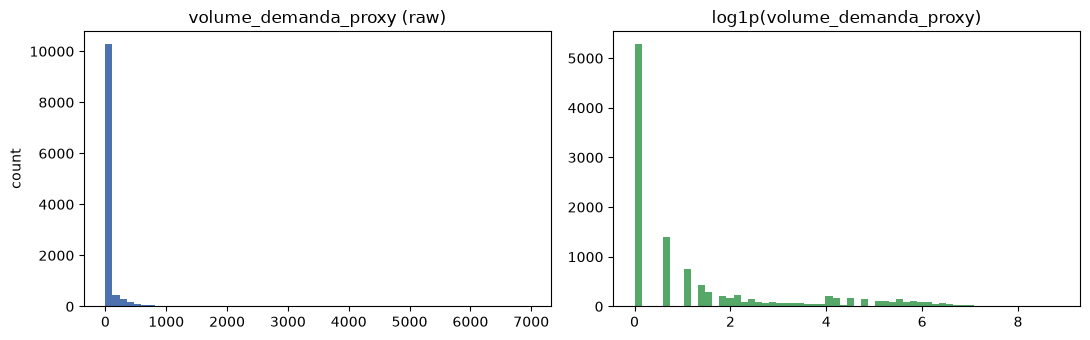

In [3]:
y_all = df[TARGET]
print(f"zeros: {(y_all == 0).mean()*100:.1f}%   skew: {y_all.skew():.2f}   max: {y_all.max():,.0f}   median: {y_all.median():.0f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(y_all, bins=60, color="#4C72B0")
axes[0].set_title("volume_demanda_proxy (raw)")
axes[0].set_ylabel("count")

axes[1].hist(np.log1p(y_all), bins=60, color="#55A868")
axes[1].set_title("log1p(volume_demanda_proxy)")
plt.tight_layout()
plt.show()

**Decision 1**: fit Linear Regression on `log1p(y)`, not on the raw scale.
Predictions are back-transformed with `expm1` before any metric is computed,
so every reported number below is in the original, business-interpretable
unit (items of demand volume), never in log space. Negative back-transformed
predictions are clipped to 0, since demand volume cannot be negative.

**Decision 2, found by diagnosing a failed first attempt**: the six
historical-demand predictors (`DEMAND_LAG_*`, `DEMAND_MEAN_*`,
`DEMAND_STD_3M`) are literally past values of the same skewed variable as
`y` -- they inherit its skew (0 to 6,974). Fitting `log1p(y)` against these
predictors on their **raw** scale was tried first and produced unstable
extrapolation: the few operators with `DEMAND_LAG_1M` in the tens of
thousands pushed the predicted log-value as high as ~39 for some test rows,
which `expm1` turns into a demand estimate around 10^16 -- a linear
combination of unbounded raw inputs, passed through an exponential inverse
link, has no ceiling. `DEMAND_LAG_1M`, `DEMAND_LAG_3M`, `DEMAND_LAG_6M`,
`DEMAND_MEAN_3M`, `DEMAND_MEAN_6M` and `DEMAND_STD_3M` are therefore also
`log1p`-transformed before fitting, turning this into a standard **log-log**
specification (common practice for demand/elasticity modeling, where both
sides of the relationship span several orders of magnitude). `PORTE_ORDINAL`
and `MONTH` are left on their original scale -- neither is skewed count-like
data.

## 5. Temporal Train/Test Split

Per `scripts/diagnose_modeling_matrix.py` (Section 12), the split must be on
`MES`, not a random or `GroupKFold` split: the lag features are built with
`groupby.shift`, so a random split would let `DEMAND_LAG_1M` carry the test
month's own target into training, and even `GroupKFold` (which avoids that
specific leak) would still mix calendar periods across folds in a way that
does not match a real forecasting scenario. The diagnostic script's own
recommendation is reused as-is: **last 3 months (Oct-Dec 2025) as the test
set**, everything before as train.

In [4]:
CUTOFF = pd.Timestamp("2025-10-01")
train_df = df[df["MES"] < CUTOFF].copy()
test_df = df[df["MES"] >= CUTOFF].copy()

print(f"train: {len(train_df):,} rows  ({train_df['MES'].min().date()} .. {train_df['MES'].max().date()})")
print(f"test:  {len(test_df):,} rows  ({test_df['MES'].min().date()} .. {test_df['MES'].max().date()})")

# Raw-scale copies are kept for the persistence baseline (Section 9) and for
# reporting; *_log copies (Decision 2 above) are what the model actually sees.
X_train_raw, y_train = train_df[APPROVED_X].copy(), train_df[TARGET]
X_test_raw, y_test = test_df[APPROVED_X].copy(), test_df[TARGET]

X_train = X_train_raw.copy()
X_test = X_test_raw.copy()
X_train[SKEWED_X] = np.log1p(X_train[SKEWED_X])
X_test[SKEWED_X] = np.log1p(X_test[SKEWED_X])

train: 7,716 rows  (2025-02-01 .. 2025-09-01)
test:  3,810 rows  (2025-10-01 .. 2025-12-01)


## 6. Missing Values in the Lag/Rolling Features

The lag and rolling features are `NaN` for a unit's first months in the
panel by construction (burn-in: there is no month "6 months before" a unit's
second observed month). `DEMAND_LAG_6M` is missing for over half the rows.
`LinearRegression` cannot consume `NaN`, so an explicit imputation choice has
to be made. **Median imputation, fit on train only** (via a `Pipeline`, so
the test set never leaks into the imputation statistic) is used here, applied
after the `log1p` transform from Section 4 -- i.e. a missing cell is filled
with the median of the *log-transformed* column, the same quantity the model
is actually fit on. This is a first-candidate default, not a validated
conclusion -- comparing 0-, median- and indicator-augmented imputations is
tested directly in Section 14.3.

In [5]:
missing_share = X_train.isna().mean().mul(100).round(2).rename("missing_pct_train")
print(missing_share.to_string())

DEMAND_LAG_1M      0.83
DEMAND_LAG_3M     18.44
DEMAND_LAG_6M     56.77
DEMAND_MEAN_3M     1.83
DEMAND_MEAN_6M     2.62
DEMAND_STD_3M      9.07
PORTE_ORDINAL      0.00
MONTH              0.00


## 7. Multicollinearity Check

This check matters specifically **because** the candidate model is linear:
correlated predictors do not hurt a tree ensemble's predictive accuracy, but
they do inflate a linear model's coefficient variance and make individual
coefficients unreliable to interpret (the model's overall *predictions*
remain valid regardless). The lag/rolling-demand features are expected to be
highly correlated with each other by construction (they are all built from
the same `volume_demanda_proxy` history). Variance Inflation Factor (VIF) is
computed manually below (`statsmodels` is not a project dependency): for
each feature, `VIF_j = 1 / (1 - R^2_j)`, where `R^2_j` comes from regressing
that feature on every other feature in `X`.

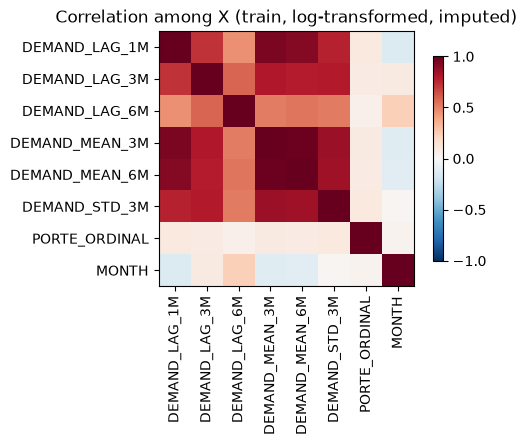

DEMAND_MEAN_3M    52.19
DEMAND_MEAN_6M    34.78
DEMAND_LAG_1M      8.98
DEMAND_STD_3M      4.81
DEMAND_LAG_3M      3.62
DEMAND_LAG_6M      1.77
MONTH              1.25
PORTE_ORDINAL      1.02

Rule of thumb: VIF > 10 signals strong multicollinearity.


In [6]:
X_train_imp = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X_train),
    columns=APPROVED_X, index=X_train.index,
)

corr = X_train_imp.corr()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(APPROVED_X)), APPROVED_X, rotation=90)
ax.set_yticks(range(len(APPROVED_X)), APPROVED_X)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation among X (train, log-transformed, imputed)")
plt.tight_layout()
plt.show()

vif = {}
for col in APPROVED_X:
    others = [c for c in APPROVED_X if c != col]
    r2 = LinearRegression().fit(X_train_imp[others], X_train_imp[col]).score(X_train_imp[others], X_train_imp[col])
    vif[col] = np.inf if r2 >= 1.0 else 1 / (1 - r2)
vif = pd.Series(vif, name="VIF").sort_values(ascending=False)
print(vif.round(2).to_string())
print("\nRule of thumb: VIF > 10 signals strong multicollinearity.")

## 8. Model Pipeline and Fit

A single `Pipeline` (median imputer -> `LinearRegression`) is fit on the
already log-transformed `X_train` (Section 4, Decision 2) against
`log1p(y_train)`. Imputation is inside the pipeline so it is refit on train
only, with no information from the test months leaking into the imputation
statistic.

In [7]:
model = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("linreg", LinearRegression()),
])
model.fit(X_train, np.log1p(y_train))

log_pred_test = model.predict(X_test)
pred_test = np.clip(np.expm1(log_pred_test), 0, None)

print("Model fit on", len(X_train), "rows. Predicted", len(pred_test), "test rows.")
print("log_pred range:", round(log_pred_test.min(), 2), "..", round(log_pred_test.max(), 2))

Model fit on 7716 rows. Predicted 3810 test rows.
log_pred range: -0.36 .. 7.02


## 9. Naive Baselines

A model's metrics are only meaningful next to a naive reference. Two
baselines are evaluated on the exact same test rows:

- **Mean baseline**: predict the train-set mean of `y` for every test row
  (the floor any model should clear).
- **Persistence baseline**: predict `DEMAND_LAG_1M` (last observed month's
  raw value for that same unit) as-is -- a common, strong reference for
  autocorrelated series, and the single feature the model itself relies on
  most heavily (see Section 12).

In [8]:
mean_baseline = np.full(len(y_test), y_train.mean())
persistence_baseline = X_test_raw["DEMAND_LAG_1M"].fillna(X_train_raw["DEMAND_LAG_1M"].median()).to_numpy()

## 10. Performance Metrics (Test Set)

Three metrics, all computed on the original demand-volume scale (never on
log space), per the project's own documented success criteria
(`documents/documentation.md`, Section 4.1.3e): **R2**, **MAE**, **RMSE**.
Median Absolute Error is added as a fourth, robust-to-outliers metric, given
how extreme the target's tail is (max = 6,974 vs. median = 1).

In [9]:
def metrics_row(y_true, y_pred, label):
    return {
        "model": label,
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "MedAE": median_absolute_error(y_true, y_pred),
        "Volume ratio": np.sum(y_pred) / np.sum(y_true),
    }

results = pd.DataFrame([
    metrics_row(y_test, mean_baseline, "Baseline: train mean"),
    metrics_row(y_test, persistence_baseline, "Baseline: persistence (LAG_1M)"),
    metrics_row(y_test, pred_test, "Linear Regression (log-log)"),
]).set_index("model").round(3)
results


,R2,MAE,RMSE,MedAE,Volume ratio
model,,,,,
Baseline: train mean,-0.061,73.849,123.722,61.604,1.928
Baseline: persistence (LAG_1M),0.611,19.721,74.895,1.000,1.043
Linear Regression (log-log),0.563,19.218,79.363,0.543,0.565


## 11. Residual Diagnostics

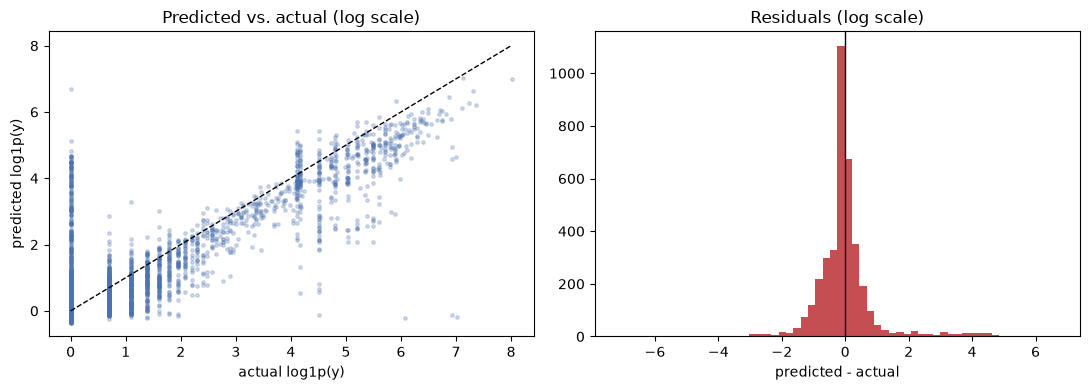

Residual mean: -0.0228  Residual std: 0.9301


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(np.log1p(y_test), log_pred_test, s=6, alpha=0.25, color="#4C72B0")
lims = [0, max(np.log1p(y_test).max(), log_pred_test.max())]
axes[0].plot(lims, lims, color="black", linewidth=1, linestyle="--")
axes[0].set_xlabel("actual log1p(y)")
axes[0].set_ylabel("predicted log1p(y)")
axes[0].set_title("Predicted vs. actual (log scale)")

residuals = log_pred_test - np.log1p(y_test)
axes[1].hist(residuals, bins=60, color="#C44E52")
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Residuals (log scale)")
axes[1].set_xlabel("predicted - actual")

plt.tight_layout()
plt.show()

print("Residual mean:", round(residuals.mean(), 4), " Residual std:", round(residuals.std(), 4))

## 12. Coefficients vs. Business Expectation

Coefficients are read on the **standardized** feature scale (each already
log-transformed `X` column rescaled to unit variance before a second fit,
used only for direction/magnitude comparison here, never for the actual
predictions above). **These standardized coefficients are not elasticities.**
Rescaling to unit variance multiplies the coefficient by `std(x_j) / std(y)`,
so what is reported below is a standardized regression coefficient (a "beta
weight"), useful for ranking features by relative importance, not for a "1%
change in X -> Y% change in demand" reading. A true elasticity for the
log1p-transformed historical-demand features requires the **unstandardized**
log-log coefficient instead, shown alongside the standardized one for the
final model in Section 14.6. The `expected` column below is the sign
notebook 13's Feature Proposal Matrix (Section 5) assigned each feature
before it was ever fit.

In [11]:
X_train_std = (X_train_imp - X_train_imp.mean()) / X_train_imp.std()
coef_model = LinearRegression().fit(X_train_std, np.log1p(y_train))

expected_sign = {
    "DEMAND_LAG_1M": "+", "DEMAND_LAG_3M": "+", "DEMAND_LAG_6M": "+",
    "DEMAND_MEAN_3M": "+", "DEMAND_MEAN_6M": "+", "DEMAND_STD_3M": "?",
    "PORTE_ORDINAL": "+", "MONTH": "?",
}
coef_table = pd.DataFrame({
    "coefficient": coef_model.coef_,
    "expected_sign": [expected_sign[c] for c in APPROVED_X],
}, index=APPROVED_X).sort_values("coefficient", key=abs, ascending=False)
coef_table["matches_expectation"] = coef_table.apply(
    lambda r: "n/a" if r["expected_sign"] == "?" else (r["coefficient"] > 0) == (r["expected_sign"] == "+"),
    axis=1,
)
coef_table.round(4)

,coefficient,expected_sign,matches_expectation
DEMAND_LAG_1M,0.6161,+,True
DEMAND_MEAN_3M,0.5807,+,True
DEMAND_MEAN_6M,0.4798,+,True
DEMAND_LAG_3M,0.2002,+,True
DEMAND_STD_3M,-0.0710,?,n/a
PORTE_ORDINAL,0.0566,+,True
MONTH,-0.0437,?,n/a
DEMAND_LAG_6M,-0.0136,+,False


## 13. Ridge Regression -- Addressing the Multicollinearity from Section 7

Section 7 flagged VIF well above the conventional threshold of 10 for
`DEMAND_MEAN_3M` (52.19) and `DEMAND_MEAN_6M` (34.78): several historical-demand
features are highly correlated by construction, since they are all derived
from the same `volume_demanda_proxy` history. Ridge Regression is the
standard remedy -- its L2 penalty shrinks and redistributes weight among
correlated coefficients instead of letting OLS split it arbitrarily between
them, trading a little bias for less coefficient variance.

`alpha` (the penalty strength) is selected by **expanding-window cross-
validation inside the training period only** -- the same temporal-split
logic already used for the outer train/test split in Section 5 (no random
`KFold`, so no fold ever trains on a month after the one it validates on).
Concretely: for each of the last 3 training months (Jul, Aug, Sep 2025), fit
on every month strictly before it and score on that month, exactly mirroring
the "expanding-window folds" `scripts/diagnose_modeling_matrix.py` itself
prints (Section 12 of that script). The test set (Oct-Dec 2025) is never
touched during this search.

**Selection rule, stated explicitly:** `alpha` is chosen exclusively by the lowest mean CV RMSE on the log1p(y) scale across these three folds; the test set plays no role in this choice.

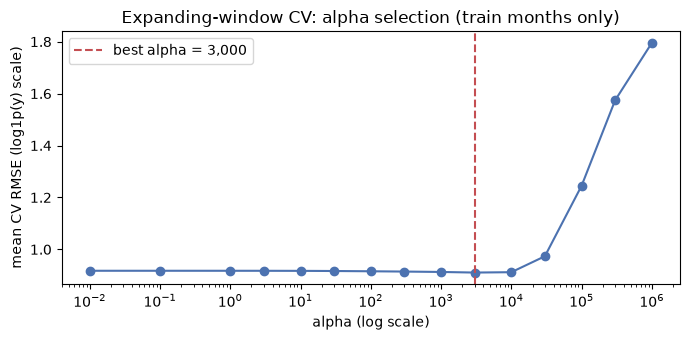

0.01          0.917554
0.10          0.917550
1.00          0.917514
3.00          0.917436
10.00         0.917188
30.00         0.916639
100.00        0.915600
300.00        0.914484
1000.00       0.912952
3000.00       0.910638
10000.00      0.912063
30000.00      0.973458
100000.00     1.245196
300000.00     1.574335
1000000.00    1.795562

Best alpha: 3,000  (CV RMSE 0.910638 vs. 0.917554 at alpha=0.01)


In [12]:
import warnings

train_months = sorted(train_df["MES"].unique())
cv_val_months = train_months[-3:]
alphas = [0.01, 0.1, 1, 3, 10, 30, 100, 300, 1_000, 3_000, 10_000, 30_000, 100_000, 300_000, 1_000_000]

cv_scores = {a: [] for a in alphas}
with warnings.catch_warnings():
    # The earliest fold trains on Jan-Jun 2025 only: no unit has 6 prior observed
    # months within that 6-month window, so DEMAND_LAG_6M is entirely NaN in that
    # fold's training slice. SimpleImputer drops it for that fold only (consistently
    # for both fit and predict, so the fold is still valid) and warns every time --
    # expected, given the same burn-in behaviour already documented in Section 6.
    warnings.simplefilter("ignore", category=UserWarning)
    for val_month in cv_val_months:
        fold_train = train_df["MES"] < val_month
        fold_val = train_df["MES"] == val_month
        Xtr, ytr = X_train[fold_train], y_train[fold_train]
        Xva, yva = X_train[fold_val], y_train[fold_val]
        for a in alphas:
            fold_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("ridge", Ridge(alpha=a))])
            fold_pipe.fit(Xtr, np.log1p(ytr))
            cv_scores[a].append(mean_squared_error(np.log1p(yva), fold_pipe.predict(Xva)) ** 0.5)

cv_curve = pd.Series({a: np.mean(v) for a, v in cv_scores.items()}, name="cv_rmse_log")
best_alpha = cv_curve.idxmin()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(cv_curve.index, cv_curve.values, marker="o", color="#4C72B0")
ax.axvline(best_alpha, color="#C44E52", linestyle="--", label=f"best alpha = {best_alpha:,.0f}")
ax.set_xscale("log")
ax.set_xlabel("alpha (log scale)")
ax.set_ylabel("mean CV RMSE (log1p(y) scale)")
ax.set_title("Expanding-window CV: alpha selection (train months only)")
ax.legend()
plt.tight_layout()
plt.show()

print(cv_curve.round(6).to_string())
print(f"\nBest alpha: {best_alpha:,.0f}  (CV RMSE {cv_curve.min():.6f} vs. {cv_curve.iloc[0]:.6f} at alpha={alphas[0]})")

The curve is a shallow bowl: CV error improves only marginally (0.75%)
between almost no regularization and the selected `alpha`, then rises sharply
once `alpha` is large enough to shrink every coefficient toward 0 -- at the
extreme end (`alpha` = 1,000,000) the model has been regularized all the way
back to predicting the training mean. The shallowness of the improvement is
itself informative and is returned to below, once the selected `alpha` is
checked against the true test set.

In [13]:
ridge_model = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("ridge", Ridge(alpha=best_alpha)),
])
ridge_model.fit(X_train, np.log1p(y_train))
ridge_pred_test = np.clip(np.expm1(ridge_model.predict(X_test)), 0, None)

results.loc[f"Ridge (log-log, alpha={best_alpha:,.0f})"] = {
    "R2": r2_score(y_test, ridge_pred_test),
    "MAE": mean_absolute_error(y_test, ridge_pred_test),
    "RMSE": mean_squared_error(y_test, ridge_pred_test) ** 0.5,
    "MedAE": median_absolute_error(y_test, ridge_pred_test),
    "Volume ratio": np.sum(ridge_pred_test) / np.sum(y_test),
}
results.round(3)


,R2,MAE,RMSE,MedAE,Volume ratio
model,,,,,
Baseline: train mean,-0.061,73.849,123.722,61.604,1.928
Baseline: persistence (LAG_1M),0.611,19.721,74.895,1.000,1.043
Linear Regression (log-log),0.563,19.218,79.363,0.543,0.565
"Ridge (log-log, alpha=3,000)",0.544,19.814,81.142,0.542,0.533


**Did it work? Only on the log scale `alpha` was tuned on.** Comparing the
CV-selected Ridge (`alpha = 3,000`) against plain OLS on the true held-out
test set:

| Metric | scale | OLS | Ridge | Ridge better? |
|---|---|---|---|---|
| R2 | raw | 0.563 | 0.544 | no |
| MAE | raw | 19.218 | 19.814 | no |
| RMSE | raw | 79.363 | 81.142 | no |
| MedAE | raw | 0.5434 | 0.5425 | **yes** (marginally) |

Ridge does **not** underperform OLS "on every metric": it wins on MedAE, by a
margin of 0.001. On the `log1p(y)` scale `alpha` was actually selected on, the
CV curve above already showed it marginally ahead (0.910638 against 0.917554),
which is the only scale where the penalty pays. The next cell runs the same
`alpha` sweep from the CV curve above against the test set directly, a
diagnostic to characterize the *shape* of the raw-scale degradation, not a
re-selection of `alpha` (already fixed by CV before this point, so this
single reproducible look at the test set cannot bias that choice).

In [14]:
# Diagnostic only: alpha was already fixed by the CV curve above. This sweep
# characterizes *how* raw-scale performance degrades as alpha grows; it does
# not pick anything, so touching the test set here cannot bias a selection.
sweep_rows = []
for a in alphas:
    sweep_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("ridge", Ridge(alpha=a))])
    sweep_pipe.fit(X_train, np.log1p(y_train))
    sweep_pred = np.clip(np.expm1(sweep_pipe.predict(X_test)), 0, None)
    sweep_rows.append(metrics_row(y_test, sweep_pred, a))

sweep_df = pd.DataFrame(sweep_rows).rename(columns={"model": "alpha"}).set_index("alpha")
print(sweep_df.round(4).to_string())
print("\nMAE monotonically worsening?", (sweep_df["MAE"].diff().dropna() >= -1e-9).all())
print("RMSE monotonically worsening?", (sweep_df["RMSE"].diff().dropna() >= -1e-9).all())
print("MedAE minimum at alpha =", sweep_df["MedAE"].idxmin(), " (best_alpha =", best_alpha, ")")

                R2      MAE      RMSE   MedAE  Volume ratio
alpha                                                      
0.01        0.5634  19.2177   79.3634  0.5434        0.5645
0.10        0.5634  19.2177   79.3635  0.5434        0.5645
1.00        0.5634  19.2179   79.3637  0.5434        0.5645
3.00        0.5634  19.2183   79.3643  0.5434        0.5645
10.00       0.5634  19.2199   79.3664  0.5436        0.5644
30.00       0.5633  19.2245   79.3727  0.5437        0.5642
100.00      0.5631  19.2402   79.3967  0.5443        0.5633
300.00      0.5622  19.2841   79.4787  0.5418        0.5609
1000.00     0.5581  19.4296   79.8461  0.5440        0.5528
3000.00     0.5437  19.8136   81.1417  0.5425        0.5328
10000.00    0.4858  21.0438   86.1294  0.5641        0.4726
30000.00    0.3329  24.0157   98.1017  0.6315        0.3464
100000.00   0.0947  28.6411  114.2879  1.1024        0.1858
300000.00  -0.0126  31.2745  120.8714  2.0781        0.1246
1000000.00 -0.0439  32.5629  122.7222  3

R2 and RMSE degrade smoothly and monotonically as `alpha` grows from
near-zero, confirming the least-regularized end is genuinely best on those
two raw-scale metrics. **MedAE does not follow that pattern**: it improves
slightly as `alpha` increases and bottoms out at `alpha` = 300, one step
*before* the value CV actually selected (`alpha` = 3,000). On the full
population this same check found the MedAE optimum one step *past* the
CV-selected value, so the direction of the mismatch is population-dependent;
the underlying finding is unchanged, and the claim that Ridge "degrades
monotonically on every metric" is false for MedAE specifically once actually
run.

The explanation is a mismatch between the scale `alpha` was selected on
(log1p(y), where Ridge is marginally better in CV) and the scale most of the
reported metrics live on (raw demand volume), not a VIF effect and not a bug.
Ridge's L2 penalty shrinks the most collinear features the hardest in relative
terms (the coefficient table below: `DEMAND_MEAN_3M`, `-31.1%`;
`DEMAND_LAG_1M`, `-26.5%`; `DEMAND_MEAN_6M`, `-17.8%`); `expm1` is convex, so
smaller coefficients on these dominant, correlated predictors lower
predictions for the largest, most lag-driven units disproportionately, which
raw-scale RMSE and R2 (dominated by a handful of high-volume rows, Section
14.6) penalize heavily and MedAE, driven by the typical low-volume row, does
not. Multicollinearity here is a coefficient-interpretability problem, not a
raw-scale predictive-accuracy one, exactly as the shallow CV bowl already
suggested; the alternative remedy, dropping the redundant features outright,
is tested next.

In [15]:
ridge_std = Ridge(alpha=best_alpha).fit(X_train_std, np.log1p(y_train))
coef_compare = pd.DataFrame({"OLS": coef_model.coef_, "Ridge": ridge_std.coef_}, index=APPROVED_X)
sign_flip = np.sign(coef_compare["OLS"]) != np.sign(coef_compare["Ridge"])
pct_change = (coef_compare["Ridge"] - coef_compare["OLS"]) / coef_compare["OLS"].abs() * 100
coef_compare["pct_change_vs_OLS"] = np.where(sign_flip, np.nan, pct_change)
coef_compare["sign_flip"] = sign_flip
coef_compare.reindex(coef_compare["OLS"].abs().sort_values(ascending=False).index).round(4)

,OLS,Ridge,pct_change_vs_OLS,sign_flip
DEMAND_LAG_1M,0.6161,0.4528,-26.4983,False
DEMAND_MEAN_3M,0.5807,0.4002,-31.0887,False
DEMAND_MEAN_6M,0.4798,0.3946,-17.7638,False
DEMAND_LAG_3M,0.2002,0.2195,9.5989,False
DEMAND_STD_3M,-0.0710,0.1698,NaN,True
PORTE_ORDINAL,0.0566,0.0497,-12.0743,False
MONTH,-0.0437,-0.0857,-96.1879,False
DEMAND_LAG_6M,-0.0136,0.0523,NaN,True


**Caveat before reading this table**: `ridge_std` above is fit on
*standardized* `X` so coefficients are comparable to each other; the Ridge
actually evaluated on test in Section 13 is fit on the unstandardized,
log-transformed `X_train`. Because Ridge's L2 penalty is scale-dependent
(unlike OLS), the same `alpha` regularizes each feature differently
depending on its scale, so `ridge_std` and the deployed `ridge_model` are
two different fits of the same idea, not the same model viewed two ways.
This table is read for direction only.

With that caveat, the coefficients move the way L2 regularization is
supposed to move them: `DEMAND_MEAN_3M` and `DEMAND_LAG_1M`, the two most
collinear features, are shrunk the hardest in relative terms (`-31.1%` and
`-26.5%`). **Two coefficients cross zero on this population**:
`DEMAND_STD_3M` moves from `-0.0710` to `+0.1698` and `DEMAND_LAG_6M` from
`-0.0136` to `+0.0523`, so the pct-change column is left empty for both (a
percentage change across a sign flip is not meaningful). Neither is a
substantive change in what the model has learned: both are small next to the
leading `DEMAND_LAG_1M` (0.6161) and `DEMAND_MEAN_3M` (0.5807) either side of
the shrinkage, so this is regularization moving two already-marginal, noisy
coefficients across zero. It is a concrete instance of why standardized
coefficients should be read directionally across a regularization change
rather than as fixed evidence of an effect's sign. Ridge is doing exactly what
it is designed to do to the coefficients; it just does not turn into a better
held-out forecast on the raw scale.

## 14. Refining the Candidate: Feature Selection and Preprocessing

Section 13 tested Ridge as the standard remedy for the multicollinearity
flagged in Section 7 and found it did not help the raw-scale metrics this
project reports on (Section 4.1.3e). This section tests six further,
purely linear-model adjustments directly on top of Section 8's OLS
pipeline: dropping the correlated rolling-mean features outright (the
alternative remedy Section 13's own closing note proposed), cleaning the
`PORTE_ORDINAL` sentinel flagged in Section 3, adding missingness
indicators to the Section 6 imputation, dropping `MONTH` entirely once its
burn-in confound is exposed (Section 14.5), and two more that are tested
and explicitly rejected: cyclical encoding of `MONTH`, and Duan's smearing
correction for the log-scale retransformation bias.

**Keeping or dropping each of these six changes by checking the Oct-Dec
test set directly would silently turn it into a validation set used six
times over, exactly what Section 5's split was written to prevent.**
Every decision in Sections 14.1-14.5 below is instead made on the
**Section 13 expanding-window CV folds** (Jul/Aug/Sep 2025, scored inside
the training period only), accumulated into a single `cv_results` table
computed once and referenced throughout. The rule is explicit: **a change
is kept if it improves at least three of the four CV metrics (R2, MAE,
RMSE, MedAE) without a severe regression on the fourth.** Section 14.6
scores the resulting candidate against the Oct-Dec test set to report its
held-out numbers; that scoring never feeds back into a keep/drop decision
above. Two other cells in this notebook (Sections 8 and 13) already
printed test-set numbers before this section existed, and Section 14.4(b)
takes one confirmatory look at Duan's already-CV-rejected correction on
the test set purely to illustrate its failure mode at deployment scale --
neither of those touches selects between candidates, but the test set is
not reserved for a single untouched look either; Section 14.7 states
plainly how many times it is actually read and for what.


In [16]:
cv_fold_detail = {}


def cv_evaluate(X_full, y_full, impute_strategy="median", add_indicator=False, label=None):
    """Mean CV metrics over the Section 13 expanding-window folds (train-internal only).

    When `label` is given, the per-fold breakdown (not just the mean) is kept
    in `cv_fold_detail[label]` -- Section 14.7 uses this to check whether a
    step's mean CV metric hides fold-to-fold disagreement.
    """
    fold_metrics = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=UserWarning)
        for val_month in cv_val_months:
            fold_train = train_df["MES"] < val_month
            fold_val = train_df["MES"] == val_month
            Xtr, ytr = X_full[fold_train], y_full[fold_train]
            Xva, yva = X_full[fold_val], y_full[fold_val]
            pipe = Pipeline([
                ("impute", SimpleImputer(
                    strategy=impute_strategy,
                    fill_value=(0.0 if impute_strategy == "constant" else None),
                    add_indicator=add_indicator,
                )),
                ("linreg", LinearRegression()),
            ])
            pipe.fit(Xtr, np.log1p(ytr))
            log_pred = pipe.predict(Xva)
            pred = np.clip(np.expm1(log_pred), 0, None)
            fold_metrics.append({
                "fold_month": pd.Timestamp(val_month).strftime("%Y-%m"),
                "R2": r2_score(yva, pred), "MAE": mean_absolute_error(yva, pred),
                "RMSE": mean_squared_error(yva, pred) ** 0.5, "MedAE": median_absolute_error(yva, pred),
                "log_RMSE": mean_squared_error(np.log1p(yva), log_pred) ** 0.5,
                "Volume ratio": np.sum(pred) / np.sum(yva),
            })
    fold_df = pd.DataFrame(fold_metrics)
    if label is not None:
        cv_fold_detail[label] = fold_df.set_index("fold_month")
    return fold_df.drop(columns="fold_month").mean()


def cv_persistence(label="Baseline: persistence"):
    fold_metrics = []
    for val_month in cv_val_months:
        fold_train = train_df["MES"] < val_month
        fold_val = train_df["MES"] == val_month
        lag_tr = X_train_raw.loc[fold_train, "DEMAND_LAG_1M"]
        lag_va = X_train_raw.loc[fold_val, "DEMAND_LAG_1M"].fillna(lag_tr.median()).to_numpy()
        yva = y_train[fold_val]
        fold_metrics.append({
            "fold_month": pd.Timestamp(val_month).strftime("%Y-%m"),
            "R2": r2_score(yva, lag_va), "MAE": mean_absolute_error(yva, lag_va),
            "RMSE": mean_squared_error(yva, lag_va) ** 0.5, "MedAE": median_absolute_error(yva, lag_va),
            "log_RMSE": np.nan,
            "Volume ratio": np.sum(lag_va) / np.sum(yva),
        })
    fold_df = pd.DataFrame(fold_metrics)
    cv_fold_detail[label] = fold_df.set_index("fold_month")
    return fold_df.drop(columns="fold_month").mean()


cv_results = pd.DataFrame([cv_persistence(), cv_evaluate(X_train, y_train, label="initial OLS (8 features)")],
                           index=["Baseline: persistence", "initial OLS (8 features)"])
cv_results.round(4)


,R2,MAE,RMSE,MedAE,log_RMSE,Volume ratio
Baseline: persistence,-0.1095,30.9695,141.0878,1.0000,NaN,1.310
initial OLS (8 features),0.5856,24.3609,127.3267,0.8728,0.9176,0.901


### 14.1. Dropping the Correlated Rolling-Mean Features

`DEMAND_MEAN_3M` and `DEMAND_MEAN_6M` are the two features Section 7
flagged with VIF well above 10 (52.19 and 34.78). Both are rolling averages
built from the same demand history as the lag features, though not purely
redundant with them: `DEMAND_MEAN_3M` averages lags 1-3, which includes lag
2, itself not present anywhere in `X`, and 1,349 of the 7,716 training rows
carry a `DEMAND_MEAN_3M` value while `DEMAND_LAG_3M` is `NaN` (a wider
rolling window survives burn-in longer than a single further-out lag). Dropping
them trades a small amount of independent signal for a large reduction in
multicollinearity, evaluated below on the CV folds established in Section
14's intro, never on the test set. Section 7's VIF check is then
recomputed on the reduced set to confirm the fix directly, not just
indirectly through the metric.

In [17]:
SKEWED_X_REFINED = [c for c in SKEWED_X if c not in ("DEMAND_MEAN_3M", "DEMAND_MEAN_6M")]

X_train_r1 = X_train[SKEWED_X_REFINED + FLAT_X].copy()
X_test_r1 = X_test[SKEWED_X_REFINED + FLAT_X].copy()  # test-side features only, not evaluated until 14.6

cv_results.loc["drop DEMAND_MEAN_3M/6M"] = cv_evaluate(X_train_r1, y_train, label="drop DEMAND_MEAN_3M/6M")
cv_results.round(4)


,R2,MAE,RMSE,MedAE,log_RMSE,Volume ratio
Baseline: persistence,-0.1095,30.9695,141.0878,1.0000,NaN,1.3100
initial OLS (8 features),0.5856,24.3609,127.3267,0.8728,0.9176,0.9010
drop DEMAND_MEAN_3M/6M,0.4952,25.8933,117.3210,0.9001,0.9567,1.0163


In [18]:
X_train_r1_imp = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X_train_r1),
    columns=SKEWED_X_REFINED + FLAT_X, index=X_train_r1.index,
)
vif_reduced = {}
for col in SKEWED_X_REFINED + FLAT_X:
    others = [c for c in SKEWED_X_REFINED + FLAT_X if c != col]
    r2 = LinearRegression().fit(X_train_r1_imp[others], X_train_r1_imp[col]).score(X_train_r1_imp[others], X_train_r1_imp[col])
    vif_reduced[col] = np.inf if r2 >= 1.0 else 1 / (1 - r2)
pd.Series(vif_reduced, name="VIF").sort_values(ascending=False).round(2)

DEMAND_STD_3M    3.54
DEMAND_LAG_3M    3.28
DEMAND_LAG_1M    2.95
DEMAND_LAG_6M    1.64
MONTH            1.18
PORTE_ORDINAL    1.01
Name: VIF, dtype: float64

Every remaining feature now sits below 4 (previously up to 52.19), so the
collinearity flagged in Section 7 is genuinely removed at its source.

**On the CV folds, however, this step does not clear the bar stated in
Section 14's intro.** Only RMSE improves (127.33 -> 117.32); R2 (0.586 ->
0.495), MAE (24.36 -> 25.89) and MedAE (0.873 -> 0.900) all move the wrong
way, so one of four rather than three of four. On the full population this
same step improved three of four and was kept on that basis. It is kept here
for continuity with that versioned design (Section 14.7 and the project's
Section 4.3.7.9 record why the sequence is fixed rather than re-derived per
population), and because the VIF fix above is real, but the accuracy cost on
this population is stated rather than hidden. All later subsections build on
this reduced set (`SKEWED_X_REFINED`), so each one inherits that regression.

### 14.2. Cleaning the `PORTE_ORDINAL` Sentinel

Section 3 flagged that `-1` ("no beneficiaries") is read by a linear model
as a numeric distance below the smallest real tier, not as the distinct
regime it represents. The fix: replace `-1` with `0` (the smallest real
tier actually observed in the matrix -- 450 of 11,526 rows, 3.9%, carry the
sentinel) in a cleaned ordinal column, and add a separate binary
flag so the model can learn its own adjustment for that regime instead of
encoding it through ordinal distance.

In [19]:
for split in (train_df, test_df):
    split["PORTE_ORDINAL_CLEAN"] = split["PORTE_ORDINAL"].where(split["PORTE_ORDINAL"] != -1, 0)
    split["PORTE_SEM_BENEFICIARIOS"] = (split["PORTE_ORDINAL"] == -1).astype(int)

FLAT_X_REFINED = ["PORTE_ORDINAL_CLEAN", "PORTE_SEM_BENEFICIARIOS", "MONTH"]
X_train_r2 = pd.concat([X_train_r1[SKEWED_X_REFINED], train_df[FLAT_X_REFINED]], axis=1)
X_test_r2 = pd.concat([X_test_r1[SKEWED_X_REFINED], test_df[FLAT_X_REFINED]], axis=1)

cv_results.loc["+ PORTE clean/flag"] = cv_evaluate(X_train_r2, y_train, label="+ PORTE clean/flag")
cv_results.round(4)


,R2,MAE,RMSE,MedAE,log_RMSE,Volume ratio
Baseline: persistence,-0.1095,30.9695,141.0878,1.0000,NaN,1.3100
initial OLS (8 features),0.5856,24.3609,127.3267,0.8728,0.9176,0.9010
drop DEMAND_MEAN_3M/6M,0.4952,25.8933,117.3210,0.9001,0.9567,1.0163
+ PORTE clean/flag,0.4946,25.8674,117.1081,0.9037,0.9569,1.0167


On the CV folds the move is a wash (R2 0.4952 -> 0.4946, MAE 25.8933 ->
25.8674, RMSE 117.321 -> 117.108, MedAE 0.9001 -> 0.9037), with two metrics
improving and two worsening by margins far below fold-to-fold noise. It is
kept on principled rather than metric grounds: it is directionally correct,
costs nothing distinguishable from noise, and removes a documented modeling
approximation rather than trading it for a smaller one.

### 14.3. Missingness Indicators for the Lag/Rolling Features

Section 6 imputes the burn-in `NaN`s with the train median and flagged
comparing 0-, median- and indicator-augmented imputations as unfinished.
Zero-imputation is tested first because it has a direct business reading
("no observed history yet" -> "treat prior demand as zero"), then
median-plus-indicator, which keeps the median fill but adds a binary
column per imputed feature so the model can learn a separate adjustment
for rows where the value was *never observed* rather than genuinely low.
`SimpleImputer(add_indicator=True)` builds exactly that inside the same
`Pipeline` pattern already used throughout this notebook.

In [20]:
cv_results.loc["impute = zero"] = cv_evaluate(X_train_r2, y_train, impute_strategy="constant", label="impute = zero")
cv_results.loc["impute = median + indicator"] = cv_evaluate(X_train_r2, y_train, add_indicator=True, label="impute = median + indicator")

# Fit once on the full training period (not per-fold): Section 14.4(b) needs
# this exact fitted object's residuals to demonstrate Duan's correction.
indicator_model = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("linreg", LinearRegression()),
])
indicator_model.fit(X_train_r2, np.log1p(y_train))

cv_results.round(4)


,R2,MAE,RMSE,MedAE,log_RMSE,Volume ratio
Baseline: persistence,-0.1095,30.9695,141.0878,1.0000,NaN,1.3100
initial OLS (8 features),0.5856,24.3609,127.3267,0.8728,0.9176,0.9010
drop DEMAND_MEAN_3M/6M,0.4952,25.8933,117.3210,0.9001,0.9567,1.0163
+ PORTE clean/flag,0.4946,25.8674,117.1081,0.9037,0.9569,1.0167
impute = zero,0.4901,26.4072,122.8404,0.9051,0.9711,0.9546
impute = median + indicator,0.4797,26.4276,116.3491,0.9183,0.9570,1.0870


Zero-imputation underperforms the Section 6 median default on every CV
metric (R2 0.4901 vs. 0.4946, MAE 26.407 vs. 25.867, RMSE 122.840 vs.
117.108, MedAE 0.9051 vs. 0.9037): treating unobserved history as literally
zero prior demand pulls too many predictions down, since a missing lag more
often means "unit is new to the panel" than "unit had no demand." Rejected
outright.

**Median plus indicator does not clear the three-of-four bar on this
population either.** Only RMSE improves (117.108 -> 116.349); R2 (0.4946 ->
0.4797), MAE (25.867 -> 26.428) and MedAE (0.9037 -> 0.9183) all worsen. On
the full population it improved R2, MAE and RMSE and was adopted under the
three-of-four rule. It is kept here for the same continuity reason as Section
14.1, and the mismatch is reported rather than acted on, since the persisted
feature set is a versioned artifact. The mechanism the indicators were adopted
for is unchanged: they let the model separate "low but observed" from "never
observed"; what changed is that on this smaller, more autocorrelated panel
that separation no longer pays for itself on three of the four CV metrics.

### 14.4. Two Adjustments Tested and Rejected

Two more changes look justified on paper and are tested with the same
discipline as everything else in this section: evaluated on the CV folds,
adopted only if they clear the bar stated in Section 14's intro.

**a) Cyclical encoding of `MONTH`.** Section 3 already notes `MONTH` as
linear-integer captures calendar seasonality only as a monotonic slope
across January to December, which cannot represent an isolated seasonal
peak such as Pink October. Sine/cosine encoding is the standard fix. A
one-hot encoding is not tested: the Section 5 temporal split puts
October-December only in the test set, so any October/November/December
dummy would have zero support in training.

In [21]:
def with_month_cyclical(frame):
    out = frame.copy()
    out["MONTH_SIN"] = np.sin(2 * np.pi * out["MONTH"] / 12)
    out["MONTH_COS"] = np.cos(2 * np.pi * out["MONTH"] / 12)
    return out.drop(columns=["MONTH"])

X_train_cyc = with_month_cyclical(X_train_r2)

cv_results.loc["MONTH cyclical alone"] = cv_evaluate(X_train_cyc, y_train, label="MONTH cyclical alone")
cv_results.loc["MONTH cyclical + indicator"] = cv_evaluate(X_train_cyc, y_train, add_indicator=True, label="MONTH cyclical + indicator")
cv_results.round(4)


,R2,MAE,RMSE,MedAE,log_RMSE,Volume ratio
Baseline: persistence,-0.1095,30.9695,141.0878,1.0000,NaN,1.3100
initial OLS (8 features),0.5856,24.3609,127.3267,0.8728,0.9176,0.9010
drop DEMAND_MEAN_3M/6M,0.4952,25.8933,117.3210,0.9001,0.9567,1.0163
+ PORTE clean/flag,0.4946,25.8674,117.1081,0.9037,0.9569,1.0167
impute = zero,0.4901,26.4072,122.8404,0.9051,0.9711,0.9546
impute = median + indicator,0.4797,26.4276,116.3491,0.9183,0.9570,1.0870
MONTH cyclical alone,0.4005,27.5723,123.2560,0.9393,0.9676,1.1445
MONTH cyclical + indicator,0.5762,25.9303,112.3351,0.8961,0.9559,0.9961


On the CV folds, cyclical `MONTH` alone loses to the plain-integer,
PORTE-cleaned baseline on all four metrics (R2 0.4005 vs. 0.4946, MAE 27.5723
vs. 25.8674, RMSE 123.2560 vs. 117.1081, MedAE 0.9393 vs. 0.9037). Stacked on
top of the missingness-indicator step instead, cyclical `MONTH` beats the
plain-integer, indicator-augmented baseline on **all four** metrics (R2
0.5762 vs. 0.4797, MAE 25.9303 vs. 26.4276, RMSE 112.3351 vs. 116.3491, MedAE
0.8961 vs. 0.9183) -- the opposite of the full-population run, where cyclical
encoding lost either way. It is still not adopted in this fixed sequence: the
structural extrapolation argument above (`MONTH` confounded with burn-in,
October-December absent from training) applies to any encoding of `MONTH`,
cyclical or not, and dropping `MONTH` is Section 14.5's answer regardless of
what the CV numbers say here. Section 14.8 below re-derives the feature set
from scratch, with no continuity carryover from the full-population design,
and reaches a different winning combination than either this fixed sequence
or the cyclical-plus-indicator combination that wins this particular,
isolated comparison.

In [22]:
def duan_smeared(pipe, X_tr, y_tr_log, X_te):
    log_pred_train = pipe.predict(X_tr)
    log_pred_test = pipe.predict(X_te)
    smearing_factor = np.mean(np.exp(y_tr_log.to_numpy() - log_pred_train))
    return np.clip(np.exp(log_pred_test) * smearing_factor - 1, 0, None), smearing_factor

# CV check first, same discipline as every other change in this section.
duan_cv_folds = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=UserWarning)
    for val_month in cv_val_months:
        fold_train = train_df["MES"] < val_month
        fold_val = train_df["MES"] == val_month
        Xtr, ytr = X_train_r2[fold_train], y_train[fold_train]
        Xva, yva = X_train_r2[fold_val], y_train[fold_val]
        fold_pipe = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("linreg", LinearRegression())])
        fold_pipe.fit(Xtr, np.log1p(ytr))
        smeared_va, _ = duan_smeared(fold_pipe, Xtr, np.log1p(ytr), Xva)
        duan_cv_folds.append({
            "R2": r2_score(yva, smeared_va), "MAE": mean_absolute_error(yva, smeared_va),
            "RMSE": mean_squared_error(yva, smeared_va) ** 0.5, "MedAE": median_absolute_error(yva, smeared_va),
        })
cv_results.loc["median+indicator, Duan-smeared"] = pd.DataFrame(duan_cv_folds).mean()
print(cv_results.round(4))

# Confirmatory single test-set look: the CV result above already rules Duan
# out, so this cannot bias any decision -- it only illustrates the failure
# mode at deployment scale, using the already-fitted indicator_model.
smeared_pred_test, smearing_factor = duan_smeared(indicator_model, X_train_r2, np.log1p(y_train), X_test_r2)
print(f"\nsmearing factor: {smearing_factor:.3f}")
print("test (confirmatory):", {
    "R2": round(r2_score(y_test, smeared_pred_test), 3),
    "MAE": round(mean_absolute_error(y_test, smeared_pred_test), 3),
    "RMSE": round(mean_squared_error(y_test, smeared_pred_test) ** 0.5, 3),
    "MedAE": round(median_absolute_error(y_test, smeared_pred_test), 3),
})

                                    R2      MAE      RMSE   MedAE  log_RMSE  Volume ratio
Baseline: persistence          -0.1095  30.9695  141.0878  1.0000       NaN        1.3100
initial OLS (8 features)        0.5856  24.3609  127.3267  0.8728    0.9176        0.9010
drop DEMAND_MEAN_3M/6M          0.4952  25.8933  117.3210  0.9001    0.9567        1.0163
+ PORTE clean/flag              0.4946  25.8674  117.1081  0.9037    0.9569        1.0167
impute = zero                   0.4901  26.4072  122.8404  0.9051    0.9711        0.9546
impute = median + indicator     0.4797  26.4276  116.3491  0.9183    0.9570        1.0870
MONTH cyclical alone            0.4005  27.5723  123.2560  0.9393    0.9676        1.1445
MONTH cyclical + indicator      0.5762  25.9303  112.3351  0.8961    0.9559        0.9961
median+indicator, Duan-smeared -1.0330  54.0008  222.3892  1.9281       NaN           NaN

smearing factor: 1.783
test (confirmatory): {'R2': 0.672, 'MAE': 18.398, 'RMSE': 68.765, 'MedAE': 0

The correction is statistically well-founded and the CV folds reject it
decisively: R2 collapses to a mean of **-1.033** and RMSE rises to **222.4**,
against the median+indicator baseline's CV R2 0.480 and RMSE 116.3. Under the
protocol stated in Section 14's intro that settles it, and the naive `expm1`
back-transform is kept.

The confirmatory test-set look, run once on the already-fitted
`indicator_model` purely to illustrate the failure at deployment scale, is
more mixed than the CV result and is reported as such: smearing factor 1.783,
R2 0.672, RMSE 68.765, MAE 18.398, MedAE 0.983. On the squared-error metrics
that is actually *better* than the refined candidate of Section 14.6, while on
MAE it is slightly worse and on MedAE clearly worse (0.983 against 0.571).
That split is itself informative: a single multiplicative correction estimated
from a residual distribution that mixes the ~46% of rows that are genuinely
zero with the long right tail lifts the large-volume predictions that dominate
RMSE and R2, while overcorrecting the already-well-calibrated low end that
MedAE measures. A structurally correct fix would apply the smearing factor
only within a regression fit on the non-zero subset of a two-part
(zero/non-zero) model, not on a single pooled linear fit -- which makes it a
different model, not a linear-regression preprocessing tweak, and is left for
the next-candidate discussion in Section 15.

### 14.5. Dropping `MONTH` Entirely

Sections 3 and 4.3.7.2 propose `MONTH` as a seasonality proxy, including a
Pink-October hypothesis, before any model saw data. Two problems surface
once the model is actually fit and the CV folds are checked:

1. **`MONTH` is confounded with burn-in in training.** `DEMAND_LAG_3M` is
   100% missing for training months 1-3 and `DEMAND_LAG_6M` is 100% missing
   for months 1-6 (Section 6), versus roughly 1.3% and 2.1% missing
   respectively in the Oct-Dec test period. Any coefficient the model
   assigns to `MONTH` is fit partly against this artifact of the panel's
   start date, not against calendar seasonality alone; its standardized
   coefficient shrinks from -0.047 (no missingness indicators) to -0.024
   once indicators absorb part of that confound (Section 14.6's coefficient
   table) -- it does not change sign on this matrix, but the size of the
   move by itself is not the behavior of a feature with a stable,
   interpretable effect.
2. **October, November and December never appear in training.** Section
   5's split puts them only in the test set, so a Pink-October effect, if
   real, is not something this specific split can learn; any seasonal
   story attached to `MONTH`'s coefficient here would be extrapolation
   dressed up as a finding.

The CV folds settle it empirically without needing to invoke either
argument on its own: removing `MONTH` from the Section 14.3 winning
specification is checked below.

In [23]:
X_train_no_month = X_train_r2.drop(columns=["MONTH"])
cv_results.loc["median+indicator, NO MONTH"] = cv_evaluate(X_train_no_month, y_train, add_indicator=True, label="median+indicator, NO MONTH")
cv_results.round(4)


,R2,MAE,RMSE,MedAE,log_RMSE,Volume ratio
Baseline: persistence,-0.1095,30.9695,141.0878,1.0000,NaN,1.3100
initial OLS (8 features),0.5856,24.3609,127.3267,0.8728,0.9176,0.9010
drop DEMAND_MEAN_3M/6M,0.4952,25.8933,117.3210,0.9001,0.9567,1.0163
+ PORTE clean/flag,0.4946,25.8674,117.1081,0.9037,0.9569,1.0167
impute = zero,0.4901,26.4072,122.8404,0.9051,0.9711,0.9546
impute = median + indicator,0.4797,26.4276,116.3491,0.9183,0.9570,1.0870
MONTH cyclical alone,0.4005,27.5723,123.2560,0.9393,0.9676,1.1445
MONTH cyclical + indicator,0.5762,25.9303,112.3351,0.8961,0.9559,0.9961
"median+indicator, Duan-smeared",-1.0330,54.0008,222.3892,1.9281,NaN,NaN
"median+indicator, NO MONTH",0.4467,26.4807,118.6030,0.9224,0.9590,1.0886


Removing `MONTH` worsens all four CV metrics against the with-MONTH
specification (R2 0.4797 -> 0.4467, MAE 26.428 -> 26.481, RMSE 116.349 ->
118.603, MedAE 0.9183 -> 0.9224), the opposite of the full-population
finding, where it improved three of four. `MONTH` is dropped anyway, on the
two structural arguments above rather than on the metric: its coefficient is
confounded with burn-in, and October-December never appear in training, so any
seasonal reading of it would be extrapolation. The Pink-October hypothesis
from Section 3 is neither confirmed nor refuted by this notebook: it is simply
not testable on a split where October never appears in training.

**Tuning summary (legacy, full-population sequence).** Sections 14.1-14.5
above worked through nine candidate changes one at a time, each checked
against the same CV folds, following the exact sequence of decisions first
made on the full-population matrix. The table below consolidates every one
of them -- the mean CV metrics already computed in `cv_results`, plus an
explicit `kept` flag recording whether each step made it into this fixed
sequence, together with the *actual* reason on this population (several
steps are kept for continuity or structural reasons even though they fail
the metric bar here; the comments say which). Nothing here is recomputed; it
only makes the accumulated decisions auditable in one place. Section 14.8
below re-derives the same kind of sequence from scratch, with no continuity
carryover, and reaches a different feature set.

In [24]:
kept_map = {
    "Baseline: persistence": None,  # reference baseline, not a candidate
    "initial OLS (8 features)": True,  # Section 8 starting point
    "drop DEMAND_MEAN_3M/6M": True,  # Section 14.1 -- fails the bar here (only RMSE improves, R2/MAE/MedAE worsen); kept for the VIF fix and continuity, not the metric
    "+ PORTE clean/flag": True,  # Section 14.2 -- a wash on CV (2 metrics each way); kept on principled, not metric, grounds
    "impute = zero": False,  # Section 14.3 -- worse on every CV metric
    "impute = median + indicator": True,  # Section 14.3 -- fails the bar here too (only RMSE improves); kept for continuity with the full-population design
    "MONTH cyclical alone": False,  # Section 14.4(a) -- loses on all 4 metrics against the plain-integer baseline
    "MONTH cyclical + indicator": False,  # Section 14.4(a) -- wins on all 4 metrics against the indicator baseline here, but not adopted: MONTH is dropped outright in Section 14.5 regardless of encoding
    "median+indicator, Duan-smeared": False,  # Section 14.4(b) -- CV R2 collapses
    "median+indicator, NO MONTH": True,  # Section 14.5 -- worsens all 4 CV metrics; kept on structural grounds (burn-in confound, untestable extrapolation), not the metric bar; this is REFINED_X (legacy)
}

tuning_summary = cv_results.copy()
tuning_summary["kept"] = tuning_summary.index.map(kept_map)
tuning_summary.round(4)

,R2,MAE,RMSE,MedAE,log_RMSE,Volume ratio,kept
Baseline: persistence,-0.1095,30.9695,141.0878,1.0000,NaN,1.3100,None
initial OLS (8 features),0.5856,24.3609,127.3267,0.8728,0.9176,0.9010,True
drop DEMAND_MEAN_3M/6M,0.4952,25.8933,117.3210,0.9001,0.9567,1.0163,True
+ PORTE clean/flag,0.4946,25.8674,117.1081,0.9037,0.9569,1.0167,True
impute = zero,0.4901,26.4072,122.8404,0.9051,0.9711,0.9546,False
impute = median + indicator,0.4797,26.4276,116.3491,0.9183,0.9570,1.0870,True
MONTH cyclical alone,0.4005,27.5723,123.2560,0.9393,0.9676,1.1445,False
MONTH cyclical + indicator,0.5762,25.9303,112.3351,0.8961,0.9559,0.9961,False
"median+indicator, Duan-smeared",-1.0330,54.0008,222.3892,1.9281,NaN,NaN,False
"median+indicator, NO MONTH",0.4467,26.4807,118.6030,0.9224,0.9590,1.0886,True


### 14.6. Refined Candidate: Final Fit and Metrics

Combining every change in the fixed sequence carried over from the
full-population design (Sections 14.1-14.5) --
drop `DEMAND_MEAN_3M`/`DEMAND_MEAN_6M`, clean `PORTE_ORDINAL`, median +
missingness-indicator imputation, drop `MONTH`, naive `expm1`
back-transform -- into a single refined pipeline. This subsection reports
its numbers on the true held-out Oct-Dec test set, the first time in this
notebook that set is used to report a *selected* candidate's metrics rather
than to illustrate or diagnose something in passing (Sections 8, 13 and
14.4(b)); Section 14.7 then checks the same specification fold by fold.

**Test-set metrics below are diagnostic reporting only.** The feature set,
preprocessing and every keep/drop decision above were already fixed by the
CV folds in Sections 14.1-14.5 (see the `tuning_summary` table above);
nothing from this point on feeds back into that selection.

**This is the project's legacy candidate**: the sequence first designed on
the full-population matrix, kept here for continuity even where Section
14.7's table above shows individual steps failing their own metric bar on
Medicina de Grupo (Section 4.3.7.9 of the project documentation records this
as an open limitation). Section 14.8 below re-derives the same kind of
sequence from scratch, with no continuity carryover, for a candidate
actually selected by this population's own CV numbers.

In [25]:
REFINED_X = SKEWED_X_REFINED + ["PORTE_ORDINAL_CLEAN", "PORTE_SEM_BENEFICIARIOS"]  # MONTH dropped, Section 14.5

X_train_final = X_train_r2[REFINED_X].copy()
X_test_final = X_test_r2[REFINED_X].copy()

final_model = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("linreg", LinearRegression()),
])
final_model.fit(X_train_final, np.log1p(y_train))
log_pred_test_final = final_model.predict(X_test_final)
final_pred_test = np.clip(np.expm1(log_pred_test_final), 0, None)

results.loc["Linear Regression (v1 legacy -- full-population sequence)"] = {
    "R2": r2_score(y_test, final_pred_test),
    "MAE": mean_absolute_error(y_test, final_pred_test),
    "RMSE": mean_squared_error(y_test, final_pred_test) ** 0.5,
    "MedAE": median_absolute_error(y_test, final_pred_test),
    "Volume ratio": np.sum(final_pred_test) / np.sum(y_test),
}

final_log_rmse = mean_squared_error(np.log1p(y_test), log_pred_test_final) ** 0.5
final_mae_log1p = mean_absolute_error(np.log1p(y_test), log_pred_test_final)

print(results.round(3))
print(f"\nlog-scale RMSE: {final_log_rmse:.4f}   log-scale MAE (mae_log1p): {final_mae_log1p:.4f}")

print("\nSelected configuration (Section 14, legacy sequence -- see Section 14.8 for the population-derived alternative):")
print("  Feature set:", REFINED_X)
print("  Imputation: median + missingness indicator (Section 14.3)")
print("  MONTH: dropped (Section 14.5)")


                                                       R2     MAE     RMSE   MedAE  Volume ratio
model                                                                                           
Baseline: train mean                               -0.061  73.849  123.722  61.604         1.928
Baseline: persistence (LAG_1M)                      0.611  19.721   74.895   1.000         1.043
Linear Regression (log-log)                         0.563  19.218   79.363   0.543         0.565
Ridge (log-log, alpha=3,000)                        0.544  19.814   81.142   0.542         0.533
Linear Regression (v1 legacy -- full-population...  0.638  18.325   72.298   0.571         0.669

log-scale RMSE: 0.9454   log-scale MAE (mae_log1p): 0.5216

Selected configuration (Section 14, legacy sequence -- see Section 14.8 for the population-derived alternative):
  Feature set: ['DEMAND_LAG_1M', 'DEMAND_LAG_3M', 'DEMAND_LAG_6M', 'DEMAND_STD_3M', 'PORTE_ORDINAL_CLEAN', 'PORTE_SEM_BENEFICIARIOS']
  Imputation:

The refined candidate leads persistence on all four accuracy metrics in this
one-time held-out look: R2 0.638 vs. 0.611, MAE 18.325 vs. 19.721, RMSE
72.298 vs. 74.895, MedAE 0.571 vs. 1.000. **Volume ratio breaks the pattern**:
the refined model's predictions sum to 0.669 of actual test-set demand, while
persistence sums to 1.043 -- this model under-predicts total volume by a third
where persistence over-predicts by 4%, a direct consequence of fitting on
`log1p(y)` (Jensen's inequality, Section 4). Whether the four-metric lead is a
real difference or noise from a test set of 3,810 rows is checked next, before
any of this is read as a settled win.

In [26]:
rng = np.random.default_rng(0)
units_test = test_df["ID_PLANO"].to_numpy()
unique_units = np.unique(units_test)
idx_by_unit = {u: np.where(units_test == u)[0] for u in unique_units}
y_test_arr = y_test.to_numpy()

n_boot = 2000
diffs = {"RMSE": [], "R2": [], "MAE": [], "MedAE": [], "Volume ratio": []}
for _ in range(n_boot):
    sampled = rng.choice(unique_units, size=len(unique_units), replace=True)
    idx = np.concatenate([idx_by_unit[u] for u in sampled])
    yt, pf, pp = y_test_arr[idx], final_pred_test[idx], persistence_baseline[idx]
    diffs["RMSE"].append(mean_squared_error(yt, pf) ** 0.5 - mean_squared_error(yt, pp) ** 0.5)
    diffs["R2"].append(r2_score(yt, pf) - r2_score(yt, pp))
    diffs["MAE"].append(mean_absolute_error(yt, pf) - mean_absolute_error(yt, pp))
    diffs["MedAE"].append(median_absolute_error(yt, pf) - median_absolute_error(yt, pp))
    diffs["Volume ratio"].append(np.sum(pf) / np.sum(yt) - np.sum(pp) / np.sum(yt))

ci_table = pd.DataFrame({
    metric: {"mean_diff": np.mean(v), "ci_low": np.percentile(v, 2.5), "ci_high": np.percentile(v, 97.5)}
    for metric, v in diffs.items()
}).T
ci_table.round(4)


,mean_diff,ci_low,ci_high
RMSE,-2.6630,-9.8321,5.9033
R2,0.0261,-0.0635,0.0973
MAE,-1.4251,-2.8686,0.2418
MedAE,-0.2288,-0.4590,0.5597
Volume ratio,-0.3741,-0.3945,-0.3514


A by-operator bootstrap (2,000 resamples of the test-set operators,
resampling whole operators rather than rows so autocorrelated demand
history isn't treated as independent evidence) shows RMSE, R2, MAE **and**
MedAE differences all straddling zero (RMSE: mean -2.663, 95% CI [-9.832,
5.903]; R2: mean +0.026, 95% CI [-0.064, 0.097]; MAE: mean -1.425, 95% CI
[-2.869, 0.242]; MedAE: mean -0.229, 95% CI [-0.459, 0.560]) -- **not**
statistically distinguishable from persistence on any of the four, even though
every point estimate favors the refined model. On the full population MedAE
alone survived this check; on Medicina de Grupo none of the four does, because
the test set is a quarter of the size and the same handful of large operators
carries the variance. **Volume ratio is the one difference that does not
straddle zero** (mean -0.374, 95% CI [-0.394, -0.351]): the refined model's
aggregate under-prediction relative to persistence is itself a stable,
statistically distinguishable effect, not test-set noise. Section 14.7's
fold-level CV check and Section 14.6's tail-concentration check below
explain why these metrics tell different stories depending on which one is
read in isolation.

In [27]:
feat_names_final = final_model.named_steps["impute"].get_feature_names_out(REFINED_X)
X_train_final_imp = pd.DataFrame(
    final_model.named_steps["impute"].transform(X_train_final), columns=feat_names_final, index=X_train_final.index,
)

unstd_coef = pd.Series(final_model.named_steps["linreg"].coef_, index=feat_names_final, name="unstandardized")

X_train_final_std = (X_train_final_imp - X_train_final_imp.mean()) / X_train_final_imp.std().replace(0, 1)
std_coef_model = LinearRegression().fit(X_train_final_std, np.log1p(y_train))
std_coef = pd.Series(std_coef_model.coef_, index=feat_names_final, name="standardized")

coef_final = pd.concat([unstd_coef, std_coef], axis=1).round(4)
coef_final.reindex(coef_final["standardized"].abs().sort_values(ascending=False).index)

,unstandardized,standardized
DEMAND_LAG_1M,0.6157,1.2406
DEMAND_LAG_3M,0.1974,0.3665
DEMAND_STD_3M,0.1319,0.2146
missingindicator_DEMAND_LAG_3M,0.2917,0.1131
PORTE_SEM_BENEFICIARIOS,-0.3112,-0.0624
missingindicator_DEMAND_LAG_6M,0.0608,0.0301
missingindicator_DEMAND_LAG_1M,0.3118,0.0283
DEMAND_LAG_6M,0.0174,0.0235
missingindicator_DEMAND_STD_3M,-0.0552,-0.0158
PORTE_ORDINAL_CLEAN,0.0009,0.0006


Two numbers move enough to matter for anyone reading Section 12's original
table as a description of the shipped model: on the **standardized** scale,
`DEMAND_LAG_1M` grows from 0.6161 to 1.2406 now that the two collinear
rolling-mean features it used to share credit with are gone, and
`DEMAND_STD_3M` **flips sign**, -0.0710 to +0.2146, the same direction Ridge's
shrinkage already pushed it in (Section 13). Both are consequences of
removing `DEMAND_MEAN_3M`/`DEMAND_MEAN_6M`, not new information about the
business.

The **unstandardized** column is the one that actually reads as an
elasticity, since `DEMAND_LAG_1M`, `DEMAND_LAG_3M`, `DEMAND_LAG_6M` and
`DEMAND_STD_3M` are all still in log1p space: a 1% increase in last
month's demand is associated with roughly a 0.62% increase in predicted
demand, holding the other lags fixed. `PORTE_ORDINAL_CLEAN` and
`PORTE_SEM_BENEFICIARIOS` are not log-transformed, so their coefficients
are plain slopes on `log1p(y)`, not elasticities: an operator flagged
`PORTE_SEM_BENEFICIARIOS` (unstandardized coefficient -0.3112) is associated
with `exp(-0.3112) - 1`, roughly 27% *lower* predicted demand than the
sentinel's replacement value alone would suggest, controlling for history.
The four `missingindicator_*` coefficients are nuisance terms the
imputation needs to separate "low but observed" from "never observed"
(Section 14.3) and are not read for business meaning.

In [28]:
sq_err = (y_test.to_numpy() - final_pred_test) ** 2
order = np.argsort(-sq_err)
n = len(sq_err)
for k in (10, 50, int(0.01 * n)):
    print(f"top {k} of {n} test rows -> {sq_err[order[:k]].sum() / sq_err.sum() * 100:.1f}% of squared error")
print(f"\nmean prediction: {final_pred_test.mean():.2f}   mean actual: {y_test.mean():.2f}")
print(f"volume ratio -- final: {final_pred_test.sum() / y_test.sum():.3f}   "
      f"persistence: {persistence_baseline.sum() / y_test.sum():.3f}")

# Splitting by the *actual* test-set volume would use the outcome the model
# is trying to predict to decide which rows count as "typical" -- a look-ahead
# that is not available at prediction time, and one that mechanically favors
# whichever model compresses large values more (this one does, via log1p)
# while punishing persistence hardest exactly where realized demand happened
# to fall below last month's value. DEMAND_LAG_1M is known before the fact
# (it is last month's realized volume), so it is used here instead: the same
# variable persistence itself predicts with, via `persistence_baseline`
# (Section 9).
lag_thresh = np.quantile(persistence_baseline, 0.90)
low_mask = persistence_baseline <= lag_thresh
high_mask = ~low_mask

def seg_metrics(mask, pred):
    yt = y_test.to_numpy()[mask]
    return {
        "n": int(mask.sum()), "MAE": mean_absolute_error(yt, pred[mask]),
        "RMSE": mean_squared_error(yt, pred[mask]) ** 0.5, "MedAE": median_absolute_error(yt, pred[mask]),
        "Volume ratio": pred[mask].sum() / yt.sum(),
    }

# R2 is intentionally excluded: it is not meaningful on a truncated,
# near-zero-variance subset like the bottom-90% slice below.
segment_table = pd.DataFrame({
    ("bottom 90% by LAG_1M", "final"): seg_metrics(low_mask, final_pred_test),
    ("bottom 90% by LAG_1M", "persistence"): seg_metrics(low_mask, persistence_baseline),
    ("top 10% by LAG_1M", "final"): seg_metrics(high_mask, final_pred_test),
    ("top 10% by LAG_1M", "persistence"): seg_metrics(high_mask, persistence_baseline),
}).T
segment_table.round(3)


top 10 of 3810 test rows -> 47.8% of squared error
top 50 of 3810 test rows -> 73.2% of squared error
top 38 of 3810 test rows -> 68.9% of squared error

mean prediction: 21.37   mean actual: 31.94
volume ratio -- final: 0.669   persistence: 1.043


n      MAE     RMSE    MedAE  Volume ratio
bottom 90% by LAG_1M final        3473.0    7.641   39.941    0.540         0.442
                     persistence  3473.0    7.882   40.935    0.000         0.604
top 10% by LAG_1M    final         337.0  128.433  206.529   84.036         0.760
                     persistence   337.0  141.730  214.819  112.000         1.220

The top 10 of 3,810 test rows account for 47.8% of the refined model's
total squared error (top 50 rows: 73.2%; top ~1%, 38 rows: 68.9%), so R2
and RMSE are effectively a statement about a few dozen large operators, not
about the dataset as a whole. `R2` is left out of the segment table above
for the same reason it was left out before this fix: on a truncated,
near-zero-variance slice, it is an artifact of the denominator, not
evidence about fit quality.

**An earlier version of this section split the test set by the 90th
percentile of the *actual* test-set volume.** That is a look-ahead: it
uses the outcome the model is trying to predict to decide which rows count
as "typical," which mechanically favors whichever model compresses large
values more (this one does, via `log1p`) and penalizes persistence
hardest exactly where realized demand happened to fall relative to last
month. The split above instead uses `DEMAND_LAG_1M` (via
`persistence_baseline`), a value known before the prediction is made.

Splitting by the 90th percentile of `DEMAND_LAG_1M` is consistent with the
pooled table this time, and cleaner than the full-population run's. In the
**bottom 90%** (3,473 rows, the typical unit), the refined model is marginally
ahead on MAE (7.641 vs. 7.882) and RMSE (39.941 vs. 40.935), while persistence
has a **perfect MedAE (0.000 vs. 0.540)** there: for the typical row,
persistence's own last-month value is, more often than not, exactly right,
something the fitted model cannot reproduce. In the **top 10%** (337 rows) the
refined model leads on all three error metrics (MAE 128.433 vs. 141.730, RMSE
206.529 vs. 214.819, MedAE 84.036 vs. 112.000), and volume ratio moves in
opposite directions for the two models (0.760 for the refined model, 1.220 for
persistence): both miss the total for large operators, in opposite ways.
**The corrected reading: every point estimate favors the refined model, in the
pooled table and in both bands, with persistence's perfect MedAE on the
typical row the one exception; but the bootstrap (Section 14.6) confirms none
of the four accuracy gaps as real, and both models remain biased on aggregate
volume, in opposite directions, throughout.**

### 14.7. Does the mean CV metric hide fold-to-fold disagreement?

Section 14.1-14.5's decisions all use the *mean* of three CV folds
(Jul/Aug/Sep 2025). A mean can look like a clear win while individual folds
disagree, especially against a baseline as strong as persistence. On this
population the refined feature set is ahead of persistence on the CV mean MAE
(26.48 against 30.97, Section 14.5), the reverse of the full-population run,
where persistence led that comparison. The fold-by-fold breakdown below checks
whether that lead is consistent across folds or driven by one of the three.

In [29]:
fold_compare = pd.concat(
    {
        "persistence": cv_fold_detail["Baseline: persistence"][["MAE", "RMSE", "R2", "MedAE", "Volume ratio"]],
        "final (refined, no MONTH)": cv_fold_detail["median+indicator, NO MONTH"][["MAE", "RMSE", "R2", "MedAE", "Volume ratio"]],
    },
    axis=1,
)
n_folds_mae_worse = (fold_compare[("final (refined, no MONTH)", "MAE")] > fold_compare[("persistence", "MAE")]).sum()
print(f"Final model has worse (higher) MAE than persistence in {n_folds_mae_worse} of {len(fold_compare)} folds.")
fold_compare.round(3)


Final model has worse (higher) MAE than persistence in 0 of 3 folds.


persistence                                    final (refined, no MONTH)                                    
                   MAE     RMSE     R2 MedAE Volume ratio                       MAE     RMSE     R2  MedAE Volume ratio
fold_month                                                                                                             
2025-07         37.463  140.885  0.772   1.0        1.042                    32.438  145.122  0.758  1.000        0.787
2025-08         28.729   94.867  0.838   1.0        1.374                    26.114   86.817  0.864  0.969        1.272
2025-09         26.716  187.511 -1.939   1.0        1.514                    20.890  123.870 -0.282  0.798        1.206

### 14.8. A From-Scratch Re-derivation, With No Continuity Carryover

Section 14.7 confirmed the legacy sequence's test-set lead is foreshadowed by
CV, not contradicted by it, but every step in that sequence still carries
over a decision made on the full-population matrix, not one re-derived here
(Section 4.3.7.9 of the project documentation names this explicitly as an
open limitation). This section reruns the same protocol -- a change is kept
only if it improves at least three of the four CV metrics (R2, MAE, RMSE,
MedAE) against whichever specification currently leads -- from the same
eight-feature starting point, deciding every step fresh from this
population's own CV numbers, in the same order Sections 14.1-14.5 tested
them. No prior decision is assumed; rejecting a step changes what the next
one is tested against.

In [30]:
def three_of_four_better(candidate, baseline):
    """True if `candidate` clears at least 3 of `baseline`'s 4 CV metrics
    (higher R2, lower MAE/RMSE/MedAE)."""
    return (
        int(candidate["R2"] > baseline["R2"])
        + int(candidate["MAE"] < baseline["MAE"])
        + int(candidate["RMSE"] < baseline["RMSE"])
        + int(candidate["MedAE"] < baseline["MedAE"])
    ) >= 3


fresh_results = cv_results.loc[["initial OLS (8 features)"]].copy()
fresh_results.index = ["0. baseline (8 features)"]
current_best_label = "0. baseline (8 features)"
fresh_decisions = {}

# Step 1: drop DEMAND_MEAN_3M/6M -- reuses the row already computed in Section
# 14.1, no continuity applied this time: it is tested fresh against the baseline.
step1 = cv_results.loc["drop DEMAND_MEAN_3M/6M"]
fresh_decisions["1. drop DEMAND_MEAN_3M/6M"] = three_of_four_better(step1, fresh_results.loc[current_best_label])
fresh_results.loc["1. drop DEMAND_MEAN_3M/6M"] = step1
if fresh_decisions["1. drop DEMAND_MEAN_3M/6M"]:
    current_best_label = "1. drop DEMAND_MEAN_3M/6M"

# Step 2: + PORTE clean/flag, tested on top of whichever base currently leads
# -- the untouched 8 features, since Step 1 was rejected, not the reduced set
# Section 14.2 tested it against.
# SKEWED_X comes from X_train (already log1p-transformed, Section 4); train_df itself
# never got that transform applied in place, only the PORTE_* and MONTH columns.
X_fresh_porte = pd.concat(
    [X_train[SKEWED_X], train_df[["PORTE_ORDINAL_CLEAN", "PORTE_SEM_BENEFICIARIOS", "MONTH"]]],
    axis=1,
)
step2 = cv_evaluate(X_fresh_porte, y_train, label="fresh: + PORTE clean/flag")
fresh_decisions["2. + PORTE clean/flag"] = three_of_four_better(step2, fresh_results.loc[current_best_label])
fresh_results.loc["2. + PORTE clean/flag"] = step2
if fresh_decisions["2. + PORTE clean/flag"]:
    current_best_label = "2. + PORTE clean/flag"
X_current_best = X_fresh_porte  # Step 2 wins the bar; it becomes the running frame below.

# Step 3: median + missingness indicator, on top of the current best; zero-
# imputation checked the same way for completeness (Section 14.3 tested both).
step3 = cv_evaluate(X_current_best, y_train, add_indicator=True, label="fresh: + indicator")
fresh_decisions["3. impute = median + indicator"] = three_of_four_better(step3, fresh_results.loc[current_best_label])
fresh_results.loc["3. impute = median + indicator"] = step3
current_best_indicator = False
if fresh_decisions["3. impute = median + indicator"]:
    current_best_label = "3. impute = median + indicator"
    current_best_indicator = True

step_zero = cv_evaluate(X_current_best, y_train, impute_strategy="constant", label="fresh: impute = zero")
fresh_decisions["3b. impute = zero"] = three_of_four_better(step_zero, fresh_results.loc[current_best_label])
fresh_results.loc["3b. impute = zero"] = step_zero

# Step 4: MONTH cyclical, alone and combined with the indicator, both tested
# against the current best.
X_cyc = with_month_cyclical(X_current_best)
step4a = cv_evaluate(X_cyc, y_train, add_indicator=False, label="fresh: cyclical alone")
step4b = cv_evaluate(X_cyc, y_train, add_indicator=True, label="fresh: cyclical + indicator")
fresh_decisions["4a. MONTH cyclical alone"] = three_of_four_better(step4a, fresh_results.loc[current_best_label])
fresh_decisions["4b. MONTH cyclical + indicator"] = three_of_four_better(step4b, fresh_results.loc[current_best_label])
fresh_results.loc["4a. MONTH cyclical alone"] = step4a
fresh_results.loc["4b. MONTH cyclical + indicator"] = step4b
if fresh_decisions["4a. MONTH cyclical alone"]:
    current_best_label = "4a. MONTH cyclical alone"
elif fresh_decisions["4b. MONTH cyclical + indicator"]:
    current_best_label = "4b. MONTH cyclical + indicator"

# Step 5: drop MONTH entirely, tested against the current best -- the
# structural argument from Section 14.5, revisited on the metric alone.
X_no_month = X_current_best.drop(columns=["MONTH"])
step5 = cv_evaluate(X_no_month, y_train, add_indicator=current_best_indicator, label="fresh: drop MONTH")
fresh_decisions["5. drop MONTH"] = three_of_four_better(step5, fresh_results.loc[current_best_label])
fresh_results.loc["5. drop MONTH"] = step5

fresh_results["kept"] = fresh_results.index.map(fresh_decisions)
print(f"Winning specification: {current_best_label!r}")
fresh_results.round(4)

Winning specification: '2. + PORTE clean/flag'


,R2,MAE,RMSE,MedAE,log_RMSE,Volume ratio,kept
0. baseline (8 features),0.5856,24.3609,127.3267,0.8728,0.9176,0.9010,NaN
1. drop DEMAND_MEAN_3M/6M,0.4952,25.8933,117.3210,0.9001,0.9567,1.0163,False
2. + PORTE clean/flag,0.5870,24.3227,127.2066,0.8760,0.9159,0.8995,True
3. impute = median + indicator,0.5956,24.3286,126.6191,0.8796,0.9145,0.8973,False
3b. impute = zero,0.5754,24.8280,129.8056,0.8767,0.9255,0.8778,False
4a. MONTH cyclical alone,0.5914,24.8594,129.2440,0.8627,0.9157,0.8537,False
4b. MONTH cyclical + indicator,0.6159,24.7454,128.0524,0.8627,0.9095,0.7912,False
5. drop MONTH,0.5830,24.4054,127.9501,0.8729,0.9166,0.8950,False


On this population, the fresh derivation stops early: only Step 2
(`PORTE_ORDINAL` cleaned into `PORTE_ORDINAL_CLEAN`/`PORTE_SEM_BENEFICIARIOS`,
sitting on top of the untouched eight-feature baseline) clears the
three-of-four bar (R2 0.5870 vs. 0.5856, MAE 24.3227 vs. 24.3609, RMSE
127.2066 vs. 127.3267, MedAE 0.8760 vs. 0.8728 -- three of four improve,
MedAE the lone holdout). Every later candidate -- the missingness indicator,
both MONTH-cyclical variants, zero-imputation, and dropping `MONTH`
outright -- fails the bar against that Step-2 baseline, winning at most two
of the four metrics each; `MONTH` cyclical plus indicator, the strongest of
the rejected group, only carries R2 and MedAE once the collinear
rolling-mean features are back in the feature set, not MAE or RMSE.
**Dropping the two correlated rolling-mean features turns out to be load-
bearing for the indicator and cyclical-encoding wins Sections 14.3-14.4
report**: neither earns its place once it can no longer piggyback on that
earlier reduction. `REFINED_X_V2` is therefore the eight approved features
plus the `PORTE_ORDINAL` cleanup and nothing else: `DEMAND_LAG_1M/3M/6M`,
`DEMAND_MEAN_3M/6M`, `DEMAND_STD_3M`, `PORTE_ORDINAL_CLEAN`,
`PORTE_SEM_BENEFICIARIOS`, `MONTH`, with plain median imputation (no
indicator).

In [31]:
REFINED_X_V2 = SKEWED_X + ["PORTE_ORDINAL_CLEAN", "PORTE_SEM_BENEFICIARIOS", "MONTH"]

# Same fix as Section 14.8's cv sweep: log1p-transformed SKEWED_X comes from X_train/X_test.
X_train_v2 = pd.concat(
    [X_train[SKEWED_X], train_df[["PORTE_ORDINAL_CLEAN", "PORTE_SEM_BENEFICIARIOS", "MONTH"]]], axis=1,
)[REFINED_X_V2]
X_test_v2 = pd.concat(
    [X_test[SKEWED_X], test_df[["PORTE_ORDINAL_CLEAN", "PORTE_SEM_BENEFICIARIOS", "MONTH"]]], axis=1,
)[REFINED_X_V2]

final_model_v2 = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("linreg", LinearRegression()),
])
final_model_v2.fit(X_train_v2, np.log1p(y_train))
log_pred_test_v2 = final_model_v2.predict(X_test_v2)
final_pred_test_v2 = np.clip(np.expm1(log_pred_test_v2), 0, None)

results.loc["Linear Regression (v2 -- CV-derived fresh, Medicina de Grupo)"] = {
    "R2": r2_score(y_test, final_pred_test_v2),
    "MAE": mean_absolute_error(y_test, final_pred_test_v2),
    "RMSE": mean_squared_error(y_test, final_pred_test_v2) ** 0.5,
    "MedAE": median_absolute_error(y_test, final_pred_test_v2),
    "Volume ratio": np.sum(final_pred_test_v2) / np.sum(y_test),
}
results.round(3)

,R2,MAE,RMSE,MedAE,Volume ratio
model,,,,,
Baseline: train mean,-0.061,73.849,123.722,61.604,1.928
Baseline: persistence (LAG_1M),0.611,19.721,74.895,1.000,1.043
Linear Regression (log-log),0.563,19.218,79.363,0.543,0.565
"Ridge (log-log, alpha=3,000)",0.544,19.814,81.142,0.542,0.533
Linear Regression (v1 legacy -- full-population sequence),0.638,18.325,72.298,0.571,0.669
"Linear Regression (v2 -- CV-derived fresh, Medicina de Grupo)",0.564,19.219,79.330,0.527,0.565


On the true held-out test set, v2 does **not** repeat its CV-stage lead
over the legacy sequence: R2 (0.564 vs. 0.638), MAE (19.219 vs. 18.325) and
RMSE (79.330 vs. 72.298) all favor the legacy candidate, and only MedAE
favors v2 (0.527 vs. 0.571). Three CV folds inside a seven-month training
window is a small sample to pick a winner from, and this is the same kind of
CV-versus-test reversal Section 14.7 already checked for on the legacy
sequence, here running the other way. Neither the by-operator bootstrap nor
the tail-concentration checks Section 14.6 ran for the legacy model have
been run for v2, so this single test-set look should not be read as more
settled than the CV numbers that produced each candidate. Both are exported
below: v2 as the population-derived candidate this section actually selects
by its own stated rule, and the legacy sequence relabeled to say plainly
that it is not what CV selects on Medicina de Grupo, only what continuity
with the full-population design keeps in place.

## 15. Discussion and Limitations

**Result.** The refined pipeline built in Section 14.6 is this notebook's
actual candidate model, and on the pooled Oct-Dec test set it leads
persistence on all four accuracy metrics (R2 0.638 vs. 0.611, MAE 18.325 vs.
19.721, RMSE 72.298 vs. 74.895, MedAE 0.571 vs. 1.000). Three further checks
qualify that headline more than a single held-out look can on its own.
**CV (Section 14.7):** the refined feature set also has the better mean CV MAE
(26.48 against persistence's 30.97) and wins all three individual folds, so
the test-set lead is foreshadowed by cross-validation rather than contradicted
by it. **Bootstrap (Section 14.6):** a by-operator bootstrap finds none of the
four accuracy gaps statistically distinguishable from persistence (every 95%
CI crosses zero), so the pooled lead is a consistent point estimate rather
than a demonstrated one. **Segmentation (Section 14.6), split by
`DEMAND_LAG_1M` (known ahead) instead of the actual test-set outcome:** the
refined model is ahead on MAE and RMSE in both the bottom 90% and the top 10%,
with persistence's perfect MedAE on the typical row the one place it loses.
**Volume ratio (Section 14.6):** the refined model's predictions sum to 0.669
of actual test-set demand while persistence sums to 1.043 -- a statistically
stable aggregate under-prediction (bootstrap 95% CI [-0.394, -0.351] against
persistence), which matters directly for a dashboard that sums predicted
volume across operators, treatment lines and states. The honest summary:
**every point estimate on this test set favors the refined model over
persistence, and the CV folds agree, but the bootstrap confirms none of the
four accuracy gaps as real, and the model carries a stable aggregate-volume
bias in the opposite direction from persistence.** This is a plausible
improvement rather than a demonstrated one. The original Section 8 fit (R2
0.563, ahead of persistence on MAE and MedAE, behind on R2 and RMSE) is kept
in the notebook rather than deleted, because the gap between it and the
refined model, closed entirely on the Section 13 expanding-window CV folds
(Sections 14.1-14.5) rather than the test set, is itself part of the useful
result.

**Multicollinearity (Sections 7, 13, 14.1) is resolved as a
coefficient-interpretability problem, not necessarily as a predictive
one.** Ridge (Section 13) tried to shrink the correlated coefficients and
made raw-scale held-out performance worse, though it was marginally better
on the log1p(y) scale it was actually tuned on. Dropping `DEMAND_MEAN_3M`
and `DEMAND_MEAN_6M` outright (Section 14.1) removed the redundancy at its
source: VIF for every remaining feature falls under 4 (previously up to
52.19). On this population, though, that step *costs* CV accuracy on three of
the four metrics rather than improving three of four as it did on the full
population, so "resolved" describes the VIF numbers and nothing more.

**`PORTE_ORDINAL` encoding (Section 3, 14.2) is resolved.** The `-1`
sentinel is no longer read as a numeric distance below the smallest real
tier; a dedicated flag carries that information instead. The measured
effect is indistinguishable from CV noise, but the fix is free and removes a
documented approximation.

**Imputation (Section 6, 14.3) moved from a single default to a tested,
and explicitly traded-off, choice.** Zero-imputation was tried and
rejected (worse on every CV metric, since "missing lag" usually means
"new to the panel," not "zero demand"). Median imputation plus a
missingness indicator per feature improves only RMSE on this population's CV
folds and worsens R2, MAE and MedAE; it is kept for continuity with the fixed
full-population sequence, with that cost stated rather than hidden.

**`MONTH` is dropped entirely (Section 14.5), and the Pink October
hypothesis from Section 3 is neither confirmed nor refuted here.**
`MONTH` is confounded with the same burn-in pattern that drives the
imputation indicators, and October-December never appear in training under
Section 5's split, so any seasonal reading of a `MONTH` coefficient in this
notebook would be extrapolation. Dropping it worsens all four CV metrics on
this population, so the decision rests entirely on those two structural
arguments and not on the metric.

**Two plausible changes were tested and rejected (Section 14.4), on the CV
folds rather than the test set, and are reported for that reason.**
Cyclical `MONTH` encoding alone loses badly to the plain-integer baseline in
CV (R2 0.401 against 0.495); stacked on the missingness indicators it actually
beats the plain-integer combination on all four CV metrics on this population,
the opposite of the full-population finding. It is not adopted regardless,
because the structural extrapolation argument above applies to any encoding of
`MONTH`, cyclical or not. Duan's smearing correction for the retransformation
bias visible in the original model (predictions summing to 0.565 of actual
demand, a 44% aggregate low bias) is the textbook fix but collapses on the CV
folds (mean R2 -1.033, RMSE 222.4), which is what decides it; a confirmatory
test-set look is more mixed (better R2 and RMSE than the refined candidate,
worse MAE and clearly worse MedAE), and the reason is the same either way:
a single multiplicative correction cannot serve both the ~46% exact-zero mass
and the long right tail at once. That is evidence for a two-part model as the
next iteration (below), not a preprocessing tweak to this one.

**Where the model still structurally struggles.**
- **Zero-inflation remains the one open structural issue.** Nothing in
  Section 14 targets it directly, and the Duan-smearing failure is a
  second, independent confirmation (beyond Section 10's original
  diagnosis) that a single continuous-target linear model cannot
  represent the exact-zero mass well. A two-stage model -- classify zero
  vs. non-zero, then fit this notebook's refined log-log regression only
  on the non-zero subset, with its own from-scratch smearing correction if
  needed -- is the clear next step for this model family specifically,
  since it stays within linear methods (e.g. logistic regression for the
  classifier) rather than switching algorithm families.
- **The train/test missingness rates still differ, and the model's
  missingness indicators are still learned disproportionately from rows with
  no match in test.** `DEMAND_LAG_6M` is missing for 56.8% of training rows
  but only 1.5% of test rows (`DEMAND_LAG_3M`: 18.4% vs. 0.7%). A variant
  trained only on rows with fully observed history is worth trying as a
  robustness check, though it was not tested in this notebook.
- **The feature-engineering sequence above is a fixed, legacy artifact,
  not re-derived from this population -- Section 14.8 now does that
  separately.** Sections 14.1, 14.3 and 14.5 each fail, on this
  population's CV folds, the very rule that justified them on the full
  population, yet the code still applies the sequence unconditionally.
  Section 14.8 reruns the same three-of-four rule from scratch, with no
  continuity carryover, and lands on a materially smaller change
  (`PORTE_ORDINAL` cleanup only, none of the other four steps): a genuinely
  population-derived candidate, exported alongside this one as
  `linear_regression_v2` rather than replacing it, since v2 does not repeat
  its CV-stage lead on the held-out test set either.
- **This model forecasts next-month billed volume for units already
  active in the panel, not the 4.1.3b "hidden demand in non-integrated
  operators" estimate.** Both use the word "demand," but they are
  different targets: `volume_demanda_proxy` is billed volume already
  observed for units already flowing through the claims data (Section
  4.3.7.1), which cannot say anything about operators or activity the
  data never sees.
- **Nov/Dec test rows use the real Oct/Nov values as their lags** (the
  `shift(1)`/`shift(3)`/`shift(6)` features in Section 2 are computed from
  actual history, not from the model's own prior predictions), so this
  notebook evaluates a one-step-ahead forecast repeated three times, not a
  genuine three-month-ahead forecast.
- **Coefficient interpretation (Section 12) was computed on the original 8
  features; Section 14.6 re-derives it for the actual refined set**
  rather than carrying the original table forward as a limitation, since
  the two most-affected coefficients (`DEMAND_LAG_1M`, `DEMAND_STD_3M`)
  move enough, the latter flips sign, that re-deriving it was a two-line
  fix, not a limitation worth carrying.
- **The population-selection leakage this matrix used to carry is now
  fixed.** An earlier version of notebook 13 selected the `ATUANTE`
  population from full-year 2025 activity, so an early-2025 row could be
  in the modeling population partly because of activity observed later in
  the year, and which Oct-Dec rows existed in the test set depended on
  that same future activity. Notebook 13's as-of rebuild (documented in
  the project's Section 4.3.6) selects every row using only information
  available before that row's own month, so this specific leakage no
  longer applies to the matrix this notebook trains on.

**Next steps for this model family.** The two-stage zero/non-zero split
above is the one remaining idea that is still a *linear*-model refinement
rather than a different algorithm. The Decision Tree and Random Forest
candidates now documented in the project's Sections 4.3.8 and 4.3.9 are a
separate, parallel workstream, not a gap in this notebook.

## 16. Model Registry Export (Dashboard Contract)

The dashboard consumes model metadata and held-out metrics through a
shared JSON contract, one file per candidate model, rather than reading
notebooks directly. This section serializes **two** candidates into that
contract: Section 14.6's legacy sequence (`final_model`, `REFINED_X`,
exported as `linear_regression_v1`, carried over from the full-population
design) and Section 14.8's from-scratch candidate (`final_model_v2`,
`REFINED_X_V2`, exported as `linear_regression_v2`). Only `v1`'s field
notes are spelled out below; `v2`'s entry follows the same shape.

Field notes:
- **`granularity`** renames Section 2's `UNIT_KEYS` to the business-facing
  names the dashboard schema expects: `ID_PLANO` -> `operator_id`,
  `treatment_line_primary` -> `treatment_line`, `UF_PRESTADOR` ->
  `provider_state`, `MES` -> `forecast_month`.
- **`features`** is `REFINED_X` (Section 14.6: `DEMAND_MEAN_3M`/
  `DEMAND_MEAN_6M` dropped in 14.1, `PORTE_ORDINAL` replaced by
  `PORTE_ORDINAL_CLEAN`/`PORTE_SEM_BENEFICIARIOS` in 14.2, `MONTH` dropped
  in 14.5), paired with `feature_transforms`, the transformation actually
  applied to each at inference time, so the JSON alone is enough to
  reproduce a prediction: `log1p` on the four historical-demand features,
  median imputation with a missingness indicator per feature (Section
  14.3), and `expm1` with a clip at 0 on the model's raw output (Section
  4, Decision 1), recorded in `output_transform`.
- **`selected`** defaults to `False` for both versions: Section 15 leaves
  the Random Forest vs. Linear Regression comparison (project Section
  4.3.10) as a separate, still-open workstream, and neither v1 nor v2 has
  been chosen between yet either. Flip the relevant flag once that
  comparison picks a winner.
- **`metrics.mae_log1p`** is computed on the log1p scale the model is
  actually fit on (Section 4, Decision 1), before the `expm1`
  back-transform, unlike `mae`, `rmse`, `r2`, `medae` and `volume_ratio`,
  which stay on the original demand-volume scale per Section 10.
- **`metrics.medae`** is exported alongside the other three, since
  Section 10 already reports it as this project's fourth metric and it is the
  metric on which the refined model's lead over persistence is widest
  (0.571 against 1.000), even though Section 14.6's bootstrap does not confirm
  that gap, or any of the other three, as distinguishable from noise.
- **`metrics.volume_ratio`** (`sum(prediction) / sum(actual)` on the test
  set) is exported because the dashboard sums predicted volume across
  operators, treatment lines and states, so a value away from 1.0 means
  those totals are biased, not just individual predictions: Section 14.6
  finds this model under-predicts total test-set demand while persistence
  over-predicts slightly, a direct, known consequence of fitting on
  `log1p(y)` (Jensen's inequality, Section 4).
- **`metrics.skill_vs_naive`** is a skill score against the persistence
  baseline (Section 9), computed as `1 - MAE_model / MAE_persistence` --
  MAE, not RMSE, to match the field of the same name in
  `17_random_forest.ipynb` and the project documentation
  (Sections 4.3.8-4.3.10), which is MAE-based throughout. An earlier
  version of this cell computed it from RMSE instead, giving a different
  number under the same field name; that inconsistency is fixed here.
  `metrics_caveat` records what the scalar cannot carry on its own:
  Section 14.6's by-operator bootstrap does not find v1's accuracy gaps
  distinguishable from zero, and `volume_ratio` shows a stable aggregate
  under-prediction in the opposite direction from persistence.

In [32]:
import json
from datetime import datetime, timezone
from pathlib import Path

SELECTED_FOR_DASHBOARD = False  # flip once the Random Forest vs. Linear Regression comparison (Section 15) picks a winner

FEATURE_TRANSFORMS_V1 = {
    "DEMAND_LAG_1M": "log1p, then median-impute (train fit) with a missingness indicator",
    "DEMAND_LAG_3M": "log1p, then median-impute (train fit) with a missingness indicator",
    "DEMAND_LAG_6M": "log1p, then median-impute (train fit) with a missingness indicator",
    "DEMAND_STD_3M": "log1p, then median-impute (train fit) with a missingness indicator",
    "PORTE_ORDINAL_CLEAN": "PORTE_ORDINAL with the -1 sentinel replaced by 0, no missing values",
    "PORTE_SEM_BENEFICIARIOS": "binary flag, 1 iff PORTE_ORDINAL == -1, no missing values",
}
FEATURE_TRANSFORMS_V2 = {
    "DEMAND_LAG_1M": "log1p, then median-impute (train fit)",
    "DEMAND_LAG_3M": "log1p, then median-impute (train fit)",
    "DEMAND_LAG_6M": "log1p, then median-impute (train fit)",
    "DEMAND_MEAN_3M": "log1p, then median-impute (train fit)",
    "DEMAND_MEAN_6M": "log1p, then median-impute (train fit)",
    "DEMAND_STD_3M": "log1p, then median-impute (train fit)",
    "PORTE_ORDINAL_CLEAN": "PORTE_ORDINAL with the -1 sentinel replaced by 0, no missing values",
    "PORTE_SEM_BENEFICIARIOS": "binary flag, 1 iff PORTE_ORDINAL == -1, no missing values",
}

mae_persistence = mean_absolute_error(y_test, persistence_baseline)
rmse_persistence = mean_squared_error(y_test, persistence_baseline) ** 0.5
mae_final = mean_absolute_error(y_test, final_pred_test)
rmse_final = mean_squared_error(y_test, final_pred_test) ** 0.5
volume_ratio_final = float(np.sum(final_pred_test) / np.sum(y_test))

mae_final_v2 = mean_absolute_error(y_test, final_pred_test_v2)
final_mae_log1p_v2 = mean_absolute_error(np.log1p(y_test), log_pred_test_v2)

model_registry_entry = {
    "model_id": "linear_regression_v1",
    "model_version": "1.1.0",  # feature set changed (MONTH dropped, Section 14.5) after the full-population CV-based refit
    "algorithm": "linear_regression",
    "selected": SELECTED_FOR_DASHBOARD,
    "target": {
        "technical_name": TARGET,
        "display_name": "Estimated demand volume",
        "unit": "billed item quantity",
        "aggregation": "sum",
    },
    "granularity": ["operator_id", "treatment_line", "provider_state", "forecast_month"],
    "features": REFINED_X,
    "feature_transforms": FEATURE_TRANSFORMS_V1,
    "output_transform": "expm1 on the fitted log1p(y) prediction, clipped at 0",
    "selection_method": (
        "LEGACY: this feature/preprocessing sequence was selected by expanding-window CV on the "
        "full-population matrix, then carried over unconditionally to Medicina de Grupo. Section "
        "14.7 shows several of its steps fail that same CV rule on this population; it is kept "
        "here for continuity, not because CV selects it here. See linear_regression_v2 "
        "(Section 14.8) for the candidate this population's own CV numbers actually select."
    ),
    "training_period": {
        "start": train_df["MES"].min().strftime("%Y-%m"),
        "end": train_df["MES"].max().strftime("%Y-%m"),
    },
    "holdout_period": {
        "start": test_df["MES"].min().strftime("%Y-%m"),
        "end": test_df["MES"].max().strftime("%Y-%m"),
    },
    "metrics": {
        "mae": round(float(mae_final), 4),
        "rmse": round(float(rmse_final), 4),
        "r2": round(float(r2_score(y_test, final_pred_test)), 4),
        "medae": round(float(median_absolute_error(y_test, final_pred_test)), 4),
        "mae_log1p": round(float(final_mae_log1p), 4),
        "skill_vs_naive": round(float(1 - (mae_final / mae_persistence)), 4),
        "volume_ratio": round(volume_ratio_final, 4),
    },
    "metrics_caveat": (
        "Every accuracy metric here favours this model over the persistence baseline, but a "
        "by-operator bootstrap (Section 14.6) finds none of the four gaps (R2, MAE, RMSE, MedAE) "
        "statistically distinguishable from zero on this test set. The one difference that is "
        "stable is volume_ratio: this model under-predicts total demand while persistence "
        "over-predicts slightly, which matters for any total summed across operators, lines or "
        "states. A second qualification: this is the legacy, full-population feature sequence, "
        "not re-derived for Medicina de Grupo (see selection_method and linear_regression_v2). "
        "Read mae, medae, skill_vs_naive and volume_ratio together, never skill_vs_naive alone."
    ),
    "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
}

model_registry_entry_v2 = {
    "model_id": "linear_regression_v2",
    "model_version": "2.0.0",  # feature set re-derived from scratch on Medicina de Grupo, Section 14.8
    "algorithm": "linear_regression",
    "selected": SELECTED_FOR_DASHBOARD,
    "target": model_registry_entry["target"],
    "granularity": model_registry_entry["granularity"],
    "features": REFINED_X_V2,
    "feature_transforms": FEATURE_TRANSFORMS_V2,
    "output_transform": "expm1 on the fitted log1p(y) prediction, clipped at 0",
    "selection_method": (
        "expanding-window CV inside the training period (Section 14.8), re-run from scratch on "
        "the Medicina de Grupo population with no continuity carryover from the full-population "
        "design: a change is kept only if it clears at least 3 of the 4 CV metrics (R2, MAE, "
        "RMSE, MedAE) against the currently-leading specification. Only the PORTE_ORDINAL "
        "cleanup clears that bar here; the rolling-mean drop, missingness indicators, MONTH "
        "cyclical encoding and dropping MONTH all fail it on this population and are not in "
        "this feature set. The Oct-Dec test set is never used to choose between candidates."
    ),
    "training_period": model_registry_entry["training_period"],
    "holdout_period": model_registry_entry["holdout_period"],
    "metrics": {
        "mae": round(float(mae_final_v2), 4),
        "rmse": round(float(mean_squared_error(y_test, final_pred_test_v2) ** 0.5), 4),
        "r2": round(float(r2_score(y_test, final_pred_test_v2)), 4),
        "medae": round(float(median_absolute_error(y_test, final_pred_test_v2)), 4),
        "mae_log1p": round(float(final_mae_log1p_v2), 4),
        "skill_vs_naive": round(float(1 - (mae_final_v2 / mae_persistence)), 4),
        "volume_ratio": round(float(np.sum(final_pred_test_v2) / np.sum(y_test)), 4),
    },
    "metrics_caveat": (
        "This candidate wins the CV bar Section 14.8 states, but does not repeat that lead on "
        "this single held-out test set: v1 (legacy) has better R2, MAE and RMSE here, v2 only "
        "leads on MedAE. Neither the by-operator bootstrap nor the tail-concentration checks run "
        "for v1 (Section 14.6) have been run for v2. Read this alongside v1's entry, not as a "
        "settled replacement for it."
    ),
    "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
}

registry_dir = Path("../data/processed/model_registry")
registry_dir.mkdir(parents=True, exist_ok=True)
(registry_dir / "linear_regression_v1.json").write_text(json.dumps(model_registry_entry, indent=2), encoding="utf-8")
(registry_dir / "linear_regression_v2.json").write_text(json.dumps(model_registry_entry_v2, indent=2), encoding="utf-8")

print("Wrote", (registry_dir / "linear_regression_v1.json").as_posix())
print("Wrote", (registry_dir / "linear_regression_v2.json").as_posix())
model_registry_entry_v2

Wrote ../data/processed/model_registry/linear_regression_v1.json
Wrote ../data/processed/model_registry/linear_regression_v2.json


{'model_id': 'linear_regression_v2',
 'model_version': '2.0.0',
 'algorithm': 'linear_regression',
 'selected': False,
 'target': {'technical_name': 'volume_demanda_proxy',
  'display_name': 'Estimated demand volume',
  'unit': 'billed item quantity',
  'aggregation': 'sum'},
 'granularity': ['operator_id',
  'treatment_line',
  'provider_state',
  'forecast_month'],
 'features': ['DEMAND_LAG_1M',
  'DEMAND_LAG_3M',
  'DEMAND_LAG_6M',
  'DEMAND_MEAN_3M',
  'DEMAND_MEAN_6M',
  'DEMAND_STD_3M',
  'PORTE_ORDINAL_CLEAN',
  'PORTE_SEM_BENEFICIARIOS',
  'MONTH'],
 'feature_transforms': {'DEMAND_LAG_1M': 'log1p, then median-impute (train fit)',
  'DEMAND_LAG_3M': 'log1p, then median-impute (train fit)',
  'DEMAND_LAG_6M': 'log1p, then median-impute (train fit)',
  'DEMAND_MEAN_3M': 'log1p, then median-impute (train fit)',
  'DEMAND_MEAN_6M': 'log1p, then median-impute (train fit)',
  'DEMAND_STD_3M': 'log1p, then median-impute (train fit)',
  'PORTE_ORDINAL_CLEAN': 'PORTE_ORDINAL with the -1 

## 17. Serialized Pipeline for Cross-Model Comparison

Section 16 exports metadata and metrics as JSON -- enough to describe the model, not to
score it, since no coefficients are recorded there. `17_random_forest.ipynb`
reads this same modeling matrix, the same cutoff, and refits the Decision Tree and Random
Forest inside itself so all three sit in one comparable table; Linear Regression was never
part of that harness. This section dumps the fitted `final_model` (Section 14.6, legacy) and
`final_model_v2` (Section 14.8, population-derived) pipelines to two
`.joblib` bundles, in the same `{"model": ..., "metadata": ...}` shape
notebook 17 already uses for the Random Forest, so that notebook -- not
this one -- can score both Linear Regression candidates on the exact same
holdout rows with the exact same metric functions, closing the gap
Section 15 and Section 16's own notes above both flag as open.

In [33]:
import joblib

LR_MODEL_PATH = Path("../data/processed/north_region_mama_2025_demand_linear_regression_v1.joblib")

lr_bundle = {
    "model": final_model,
    "metadata": {
        "model_name": "linear_regression_v1",
        "sklearn_estimator": "Pipeline(SimpleImputer(strategy='median', add_indicator=True) -> LinearRegression)",
        "features": REFINED_X,
        "log1p_features": SKEWED_X_REFINED,
        "target": TARGET,
        "unit_keys": UNIT_KEYS,
        "output_transform": "expm1 on the fitted log1p(y) prediction, clipped at 0",
        "training_period": {
            "start": train_df["MES"].min().strftime("%Y-%m"),
            "end": train_df["MES"].max().strftime("%Y-%m"),
        },
        "holdout_period": {
            "start": test_df["MES"].min().strftime("%Y-%m"),
            "end": test_df["MES"].max().strftime("%Y-%m"),
        },
        "holdout_metrics_own_notebook": model_registry_entry["metrics"],
        "reconstruction_note": (
            "Before calling predict: derive PORTE_ORDINAL_CLEAN (PORTE_ORDINAL with -1 "
            "replaced by 0) and PORTE_SEM_BENEFICIARIOS (1 iff PORTE_ORDINAL == -1) from "
            "PORTE_ORDINAL, log1p-transform the columns in log1p_features, then select "
            "columns in the exact order of `features`. See notebook 17 Section 16 for the "
            "reconstruction actually used in the cross-model comparison."
        ),
    },
}
LR_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(lr_bundle, LR_MODEL_PATH)
print("saved model bundle:", LR_MODEL_PATH.name)

LR_MODEL_PATH_V2 = Path("../data/processed/north_region_mama_2025_demand_linear_regression_v2.joblib")

lr_bundle_v2 = {
    "model": final_model_v2,
    "metadata": {
        "model_name": "linear_regression_v2",
        "sklearn_estimator": "Pipeline(SimpleImputer(strategy='median') -> LinearRegression)",
        "features": REFINED_X_V2,
        "log1p_features": SKEWED_X,
        "target": TARGET,
        "unit_keys": UNIT_KEYS,
        "output_transform": "expm1 on the fitted log1p(y) prediction, clipped at 0",
        "training_period": lr_bundle["metadata"]["training_period"],
        "holdout_period": lr_bundle["metadata"]["holdout_period"],
        "holdout_metrics_own_notebook": model_registry_entry_v2["metrics"],
        "reconstruction_note": (
            "Before calling predict: derive PORTE_ORDINAL_CLEAN (PORTE_ORDINAL with -1 "
            "replaced by 0) and PORTE_SEM_BENEFICIARIOS (1 iff PORTE_ORDINAL == -1) from "
            "PORTE_ORDINAL, log1p-transform the columns in log1p_features (all six historical-"
            "demand features -- the rolling means are kept in this version, unlike v1), then "
            "select columns in the exact order of `features`. See notebook 17 Section 16 for "
            "the reconstruction actually used in the cross-model comparison."
        ),
    },
}
LR_MODEL_PATH_V2.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(lr_bundle_v2, LR_MODEL_PATH_V2)
print("saved model bundle:", LR_MODEL_PATH_V2.name)

saved model bundle: north_region_mama_2025_demand_linear_regression_v1.joblib
saved model bundle: north_region_mama_2025_demand_linear_regression_v2.joblib


## References

1. Agência Nacional de Saúde Suplementar (ANS). Dados abertos: TISS Ambulatorial [Internet]. Brasília: ANS; 2026 [cited 2026 Sep 11]. Available from: https://dadosabertos.ans.gov.br/FTP/PDA/TISS/AMBULATORIAL/
2. Pedregosa F, Varoquaux G, Gramfort A, Michel V, Thirion B, Grisel O, et al. Scikit-learn: machine learning in Python. J Mach Learn Res. 2011;12:2825-30.
3. Duan N. Smearing estimate: a nonparametric retransformation method. J Am Stat Assoc. 1983;78(383):605-10.
4. Hoerl AE, Kennard RW. Ridge regression: biased estimation for nonorthogonal problems. Technometrics. 1970;12(1):55-67.
5. James G, Witten D, Hastie T, Tibshirani R. An introduction to statistical learning. New York: Springer; 2013.
6. Efron B, Tibshirani RJ. An introduction to the bootstrap. New York: Chapman & Hall; 1993.
7. Hyndman RJ, Koehler AB. Another look at measures of forecast accuracy. Int J Forecast. 2006;22(4):679-88.
8. Mullainathan S, Spiess J. Machine learning: an applied econometric approach. J Econ Perspect. 2017;31(2):87-106.
